# Семинар 6. Нейросетевое ранжирование на Yambda

SASRec формирует 500 кандидатов, далее их ранжируют MLP и CatBoost. Сравниваем DCN-V2, Time2Vec и FCN. Данные — Yambda-50M, оценка на общем тестовом дне.

In [ ]:
%pip -q install catboost huggingface_hub matplotlib

import json
import math
import os
import random
from dataclasses import dataclass, replace
from pathlib import Path
from tempfile import TemporaryDirectory

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch import nn
from torch.nn import functional as F
from huggingface_hub import hf_hub_download

root = Path.cwd() / 'yambda-seminar'
root.mkdir(exist_ok=True)
torch.set_num_threads(4)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

cuda


## 1. Пайплайн

### 1.1. Данные и временной сплит

Признаки считаются строго до `T − 30 мин`, метки — за сутки `[T, T + 24 ч)`. Позитив: органическое прослушивание ≥50%. Для SASRec используем все прослушивания ≥50%. Шесть дней — train ранкера, один — val, один — test.

In [ ]:
@dataclass(frozen=True)
class Split:
    day: int; gap: int; test_start: int; window_start: int; window_end: int; train_end: int; window_days: int

    @staticmethod
    def default(last_ts=26_000_000, day=86_400, gap=1_800, window_days=7):
        test_start = last_ts - day
        window_end = test_start - gap
        window_start = window_end - window_days * day
        return Split(day, gap, test_start, window_start, window_end, window_start - gap, window_days)

    def slice_starts(self):
        # начала дней окна по возрастанию, затем начало теста
        return [self.window_start + i * self.day for i in range(self.window_days)] + [self.test_start]

    def cutoff(self, T):
        return T - self.gap


def events_before(df, T, split):
    return df[df.timestamp < split.cutoff(T)]


def events_of_day(df, T, split):
    return df[(df.timestamp >= T) & (df.timestamp < T + split.day)]


def assert_no_leak(df, T, split):
    assert len(df) == 0 or df.timestamp.max() < split.cutoff(T), 'утечка: событие позже отсечки среза'


def load_events(data_dir, quick=False, n_users=600, seed=42):
    """Прослушивания и лайки Yambda-50M; в quick-режиме — выборка n_users пользователей в обоих."""
    def fetch(name):
        path = os.path.join(data_dir, name)
        if not os.path.exists(path):
            from huggingface_hub import hf_hub_download
            hf_hub_download('yandex/yambda', name, repo_type='dataset', local_dir=data_dir)
        return path

    listens = pd.read_parquet(fetch('flat/50m/listens.parquet'),
                              columns=['uid', 'timestamp', 'item_id', 'is_organic', 'played_ratio_pct'])
    likes = pd.read_parquet(fetch('flat/50m/likes.parquet'), columns=['uid', 'timestamp', 'item_id'])
    if quick:
        keep = np.random.default_rng(seed).choice(listens.uid.unique(), n_users, replace=False)
        listens = listens[listens.uid.isin(keep)].reset_index(drop=True)
        likes = likes[likes.uid.isin(keep)].reset_index(drop=True)
    return listens, likes


def positive_listens(listens, threshold=50):
    # позитив — прослушивание, дослушанное хотя бы на 50%; это и есть история, как в семинаре 5
    return listens[listens.played_ratio_pct >= threshold]

In [ ]:
SEED = 42
K = 500
N_POPULAR = 5
HISTORY_LENGTH = 64
RETRIEVAL_EPOCHS = 10
RANKER_EPOCHS = 12
CATBOOST_ITERATIONS = 1_000

split = Split.default()
data = root / 'data'
listens, likes = load_events(data)
positives = positive_listens(listens)
print(f'{listens.uid.nunique():,} пользователей, {len(listens):,} прослушиваний')
display(listens.head())

starts = split.slice_starts()
display(pd.DataFrame({
    'назначение': ['train'] * 6 + ['val', 'test'],
    'отсечка признаков, с': [split.cutoff(start) for start in starts],
    'начало сбора меток, с': starts,
    'конец сбора меток, с (исключая)': [start + split.day for start in starts],
}))
print(f'SASRec видит события раньше {split.train_end:,} с')

flat/50m/listens.parquet: reconstructing file:   0%|          |  0.00B /  369MB            

flat/50m/listens.parquet: downloading bytes:           |  0.00B            

flat/50m/likes.parquet: reconstructing file:   0%|          |  0.00B / 7.18MB            

flat/50m/likes.parquet: downloading bytes:           |  0.00B            

9,238 пользователей, 46,467,212 прослушиваний


,uid,timestamp,item_id,is_organic,played_ratio_pct
0,100,39420,8326270,0,100
1,100,39420,1441281,0,100
2,100,39625,286361,0,100
3,100,40110,732449,0,100
4,100,40360,3397170,0,46


,назначение,"отсечка признаков, с","начало сбора меток, с","конец сбора меток, с (исключая)"
0,train,25305200,25307000,25393400
1,train,25391600,25393400,25479800
2,train,25478000,25479800,25566200
3,train,25564400,25566200,25652600
4,train,25650800,25652600,25739000
5,train,25737200,25739000,25825400
6,val,25823600,25825400,25911800
7,test,25911800,25913600,26000000


SASRec видит события раньше 25,305,200 с


### 1.2. Кандидатогенерация

SASRec: 2 блока, размерность 64, окно 50, 10 эпох. Скоры — скалярные произведения; in-batch негативы с logQ-коррекцией. Общий пул: **495 кандидатов SASRec + 5 популярных**, без повторов внутри выдачи.

In [ ]:
SOURCE_NAMES = ['Две башни', 'Популярное']


NEGATIVES = {'Равномерные': 'uniform', 'In-batch': 'inbatch', 'In-batch + logQ': 'inbatch_logq',
             'Смешанные + logQ': 'mixed_logq'}


S5_CFG = dict(max_len=50, windows_per_user=8, batch_size=64, epochs=10,
              d_model=64, n_heads=2, n_layers=2, dropout=0.2, lr=1e-3, k_max=300)


S5_ARTIFACT_FILES = {
    'two_tower': 'two_tower_{variant}.pt',     # state_dict SASRec, variant — код из NEGATIVES
    'catalog': 'catalog_item_ids.npy',         # индекс i+1 -> item_id
    'item_counts': 'item_counts.npy',          # позитивы трека в train, в порядке каталога
    'history': 'history.json',                 # кривые на валидации
    'meta': 'meta.json',                       # split, cfg, best_negatives
}


class SASRec(nn.Module):
    def __init__(self, n_items, max_len, d_model, n_heads, n_layers, dropout):
        super().__init__()
        self.item_emb = nn.Embedding(n_items + 1, d_model, padding_idx=0)
        self.pos_emb = nn.Embedding(max_len, d_model)
        layer = nn.TransformerEncoderLayer(d_model, n_heads, 4 * d_model, dropout, batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)
        self.n_heads = n_heads
        nn.init.normal_(self.item_emb.weight, std=0.02)
        nn.init.normal_(self.pos_emb.weight, std=0.02)
        with torch.no_grad():
            self.item_emb.weight[0].zero_()

    def attention_mask(self, seq):
        B, L = seq.shape
        eye = torch.eye(L, dtype=torch.bool, device=seq.device)
        future = torch.triu(torch.ones(L, L, dtype=torch.bool, device=seq.device), diagonal=1)
        pad = (seq == 0)[:, None, :].expand(B, L, L)
        return ((pad | future) & ~eye).repeat_interleave(self.n_heads, dim=0)

    def forward(self, seq):
        pos = torch.arange(seq.shape[1], device=seq.device)
        x = self.drop(self.item_emb(seq) + self.pos_emb(pos))
        x = self.encoder(x, mask=self.attention_mask(seq))
        return self.norm(x)


def make_sasrec(n_items, cfg):
    return SASRec(n_items, cfg['max_len'], cfg['d_model'], cfg['n_heads'], cfg['n_layers'], cfg['dropout'])


def make_example(chunk, max_len):
    inp, tgt = chunk[:-1][-max_len:], chunk[1:][-max_len:]
    pad = max_len - len(inp)
    return torch.as_tensor(np.pad(inp, (pad, 0)), dtype=torch.long), torch.as_tensor(np.pad(tgt, (pad, 0)), dtype=torch.long)


class WindowDataset(torch.utils.data.Dataset):
    def __init__(self, seqs, max_len, windows_per_user):
        self.max_len = max_len
        self.seqs, self.index = [], []
        for s in seqs.values():
            if len(s) < 2:
                continue
            self.index += [len(self.seqs)] * min(windows_per_user, math.ceil(len(s) / max_len))
            self.seqs.append(s)

    def __len__(self):
        return len(self.index)

    def __getitem__(self, i):
        s = self.seqs[self.index[i]]
        L = self.max_len + 1
        start = np.random.randint(0, len(s) - L + 1) if len(s) > L else 0
        return make_example(s[start:start + L], self.max_len)


def sampled_softmax_loss(model, inp, tgt, negatives, log_q, n_items):
    valid = tgt > 0
    h = model(inp)[valid]                      # [P, d]
    pos = tgt[valid]                           # [P]
    P = len(pos)
    logits, label = [], torch.arange(P, device=h.device)
    if negatives != 'uniform':                 # in-batch: столбец j — позитив позиции j, у позиции i верный столбец i
        s = h @ model.item_emb(pos).T          # [P, P]
        same = (pos[None, :] == pos[:, None]) & ~torch.eye(P, dtype=torch.bool, device=h.device)
        s = s.masked_fill(same, -torch.inf)    # тот же трек на другой позиции — не негатив
        if negatives != 'inbatch':
            s = s - (log_q[pos] + math.log(P))[None, :]
        logits.append(s)
    if negatives in ('uniform', 'mixed_logq'):
        neg = torch.randint(1, n_items + 1, (P,), device=h.device)
        s = h @ model.item_emb(neg).T          # [P, P]
        s = s.masked_fill(neg[None, :] == pos[:, None], -torch.inf)
        if negatives == 'uniform':             # верный столбец — отдельный скор позитива
            logits.append((h * model.item_emb(pos)).sum(-1, keepdim=True))
            label = torch.zeros(P, dtype=torch.long, device=h.device)
        else:
            s = s - math.log(P / n_items)
        logits.append(s)
    return F.cross_entropy(torch.cat(logits, 1), label)


def train_model(seqs, n_items, negatives, cfg, device, val_fn=None, verbose=False):
    """Обучение двух башен как в семинаре 5; hist — кривая val_fn, без неё — средний loss эпохи."""
    ds = WindowDataset(seqs, cfg['max_len'], cfg['windows_per_user'])
    dl = torch.utils.data.DataLoader(ds, batch_size=cfg['batch_size'], shuffle=True,
                                     drop_last=len(ds) > cfg['batch_size'])   # на крошечных данных — один неполный батч
    item_freq = np.bincount(np.concatenate(list(seqs.values())), minlength=n_items + 1).astype(np.float64)
    log_q = torch.tensor(np.log(np.maximum(item_freq, 1) / item_freq.sum()), dtype=torch.float32, device=device)
    model = make_sasrec(n_items, cfg).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=0.0)
    best, best_state, hist = -1, None, []
    for epoch in range(cfg['epochs']):
        model.train(); losses = []
        for inp, tgt in dl:
            loss = sampled_softmax_loss(model, inp.to(device), tgt.to(device), negatives, log_q, n_items)
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item())
        score = val_fn(model) if val_fn else epoch                    # без валидации — последняя эпоха
        hist.append(round(float(score if val_fn else np.mean(losses) if losses else np.nan), 5))
        if verbose:
            metric = 'validation score' if val_fn else 'training loss'
            print(f'SASRec, epoch {epoch + 1}/{cfg["epochs"]}: {metric}={hist[-1]:.5f}', flush=True)
        if score > best:
            best, best_state = score, {k: v.detach().clone() for k, v in model.state_dict().items()}
    if best_state is not None:
        model.load_state_dict(best_state)
    return model.eval(), hist

In [ ]:
@torch.no_grad()
def topk_dot(Q, E, k, device, batch=256):
    """Точный поиск: топ-k треков по скалярному произведению. Q — [пользователи, d], E — [треки + PAD, d]."""
    E = torch.as_tensor(E, device=device)
    k = min(k, E.shape[0] - 1)
    idx, val = [], []
    for b in range(0, len(Q), batch):
        s = torch.as_tensor(Q[b:b + batch], device=device) @ E.T
        s[:, 0] = -torch.inf                                           # PAD не рекомендуем
        t = s.topk(k, dim=1)
        idx.append(t.indices.cpu().numpy()); val.append(t.values.float().cpu().numpy())
    if not idx:
        return np.zeros((0, k), np.int64), np.zeros((0, k), np.float32)
    return np.vstack(idx), np.vstack(val)


@torch.no_grad()
def user_vectors(model, seqs, users, max_len, device, batch=512):
    model.eval()
    L, out, empty = max_len, [], np.zeros(0, np.int64)
    for b in range(0, len(users), batch):
        x = np.stack([np.pad(seqs.get(u, empty)[-L:], (L - len(seqs.get(u, empty)[-L:]), 0)) for u in users[b:b + batch]])
        out.append(model(torch.tensor(x, device=device))[:, -1].float().cpu().numpy())
    return np.vstack(out) if out else np.zeros((0, model.item_emb.embedding_dim), np.float32)


def item_vectors(model):
    return model.item_emb.weight.detach().float().cpu().numpy()


def merge(recs_list, quotas, return_depth=False):
    """Объединение без дублей: сначала каждый источник по своей квоте, потом добор до K.
    return_depth=True — ещё [пользователи, источники]: сколько позиций списка каждого источника прочитано."""
    K = sum(quotas)
    by_quota = np.argsort(quotas, kind='stable')[::-1]    # добирают сначала источники с большей квотой
    out = np.zeros((recs_list[0].shape[0], K), dtype=np.int64)
    depth = np.zeros((out.shape[0], len(recs_list)), dtype=np.int64)
    for r in range(out.shape[0]):
        chosen, pos = [], [0] * len(recs_list)
        taken = set()
        for need, order in ((quotas, range(len(recs_list))), ([K] * len(recs_list), by_quota)):   # сначала по квотам, потом добор
            for s in order:
                recs = recs_list[s]
                got = 0
                while got < need[s] and len(chosen) < K and pos[s] < recs.shape[1]:
                    t = recs[r, pos[s]]; pos[s] += 1
                    if t > 0 and t not in taken:
                        taken.add(t); chosen.append(t); got += 1
            if len(chosen) == K:
                break
        out[r, :len(chosen)] = chosen
        depth[r] = pos
    return (out, depth) if return_depth else out


def _sort_history(hist):
    # positives() не сортирует, а последовательностям нужен порядок по времени
    return hist.sort_values(['uid', 'timestamp'], kind='stable')


class Sources:
    """Два источника кандидатов: двухбашенная модель семинара 5 и популярное.
    Модель и item-сторона фиксированы, вектор пользователя — прогоном модели по истории среза."""

    def __init__(self, catalog, item_counts, tt_model, cfg, device, best_negatives='inbatch_logq', meta=None,
                 history=None):
        self.catalog = np.asarray(catalog)
        self.catalog_ext = np.concatenate([[0], self.catalog])           # индекс -> item_id, 0 — пусто
        self.item2idx = pd.Series(np.arange(1, len(self.catalog) + 1), index=self.catalog)
        self.n_items = len(self.catalog)
        self.item_counts = np.asarray(item_counts)                        # строка 0 — PAD; каталог по убыванию
        self.tt_model = tt_model.to(device).eval()
        self.cfg, self.device, self.best_negatives = dict(cfg), device, best_negatives
        self.meta, self.history = meta or {}, history or {}

    # --- обучение и артефакты ---

    @staticmethod
    def fit_quick(train_pos, cfg, device, negatives='inbatch_logq', seed=42, verbose=False):
        random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
        train = _sort_history(train_pos)
        counts = train.item_id.value_counts().sort_index().sort_values(ascending=False, kind='stable')
        catalog = counts.index.to_numpy()
        n = len(catalog)
        item_counts = np.concatenate([[0], counts.to_numpy()]).astype(np.int64)
        seqs = Sources._seqs(train, pd.Series(np.arange(1, n + 1), index=catalog))
        model, hist = train_model(seqs, n, negatives, cfg, device, verbose=verbose)
        return Sources(catalog, item_counts, model, cfg, device, best_negatives=negatives, history={negatives: hist})

    @staticmethod
    def load(art_dir, device):
        f = {k: os.path.join(art_dir, v) for k, v in S5_ARTIFACT_FILES.items()}
        meta = json.load(open(f['meta'], encoding='utf-8'))
        cfg = {**S5_CFG, **meta['cfg']}
        best = NEGATIVES.get(meta['best_negatives'], meta['best_negatives'])   # имя варианта или его код
        catalog = np.load(f['catalog'])
        counts = np.load(f['item_counts'])
        if len(counts) == len(catalog):                                   # в файле без PAD
            counts = np.concatenate([[0], counts])
        assert len(counts) == len(catalog) + 1, f'item_counts: {len(counts)} строк, ожидалось {len(catalog) + 1}'
        model = make_sasrec(len(catalog), cfg)
        model.load_state_dict(torch.load(f['two_tower'].format(variant=best), map_location=device, weights_only=True))
        history = json.load(open(f['history'], encoding='utf-8')) if os.path.exists(f['history']) else {}
        return Sources(catalog, counts, model, cfg, device, best_negatives=best, meta=meta, history=history)

    def save(self, art_dir):
        os.makedirs(art_dir, exist_ok=True)
        f = {k: os.path.join(art_dir, v) for k, v in S5_ARTIFACT_FILES.items()}
        torch.save(self.tt_model.state_dict(), f['two_tower'].format(variant=self.best_negatives))
        np.save(f['catalog'], self.catalog)
        np.save(f['item_counts'], self.item_counts[1:])
        json.dump(self.history, open(f['history'], 'w', encoding='utf-8'))
        meta = {**self.meta, 'cfg': self.cfg, 'best_negatives': self.best_negatives}
        meta.setdefault('split', {})
        json.dump(meta, open(f['meta'], 'w', encoding='utf-8'), ensure_ascii=False, indent=1)
        return art_dir

    # --- сторона пользователя на момент среза ---

    @staticmethod
    def _seqs(hist, item2idx):
        idx = hist.item_id.map(item2idx)
        d = hist.assign(idx=idx)[idx.notna().to_numpy()]                  # треки вне каталога пропускаем
        return {u: g.to_numpy().astype(np.int64) for u, g in d.groupby('uid', sort=False).idx}

    def source_recs(self, hist, users, k, with_vectors=False):
        """Топ-k двух башен и популярного в индексах каталога и их скоры, в порядке SOURCE_NAMES.
        with_vectors=True: ещё (векторы пользователей, векторы треков) двух башен; без истории вектор — NaN."""
        hist = _sort_history(hist)
        seqs = self._seqs(hist, self.item2idx)
        has = np.array([len(seqs.get(u, ())) > 0 for u in users], dtype=bool)
        U, E = user_vectors(self.tt_model, seqs, users, self.cfg['max_len'], self.device), item_vectors(self.tt_model)
        tt = topk_dot(U, E, k, self.device)
        kp = min(k, self.n_items)
        pop = (np.tile(np.arange(1, kp + 1), (len(users), 1)),          # каталог уже отсортирован по популярности
               np.tile(self.item_counts[1:kp + 1].astype(np.float64), (len(users), 1)))
        out = []
        for idx, sc in (tt, pop):
            idx, sc = np.asarray(idx, np.int64), np.asarray(sc, np.float64)
            if idx.shape[1] < k:                                          # каталог меньше k
                pad = k - idx.shape[1]
                idx, sc = np.pad(idx, ((0, 0), (0, pad))), np.pad(sc, ((0, 0), (0, pad)), constant_values=np.nan)
            out.append((idx, np.where(idx > 0, sc, np.nan)))
        out[0][0][~has] = 0; out[0][1][~has] = np.nan                     # без истории двум башням нечего сказать
        if not with_vectors:
            return out
        U = U.astype(np.float32, copy=True); U[~has] = np.nan
        return out, (U, E)

    @staticmethod
    def _dot_scores(Q, E, merged, batch=512):
        # скор u·e для каждого слота merged (индексы каталога), пустой слот — NaN
        out = np.empty(merged.shape, np.float64)
        for b in range(0, len(Q), batch):
            out[b:b + batch] = np.einsum('ud,ukd->uk', Q[b:b + batch], E[merged[b:b + batch]])
        out[merged == 0] = np.nan
        return out

    def candidates(self, hist_pos, users, k, n_popular):
        """Кандидаты (item_id, 0 — пустой слот) и признаки источников в порядке слотов.
        Объединение: k − n_popular мест двум башням, n_popular — популярному, без дублей, недобор — из другого источника.
        rank_* — место в топ-k источника (k — трека там нет);
        score_* — у двух башен u·e, у популярного число позитивов трека в train: оба есть у всех кандидатов;
        from_* — 1, если источник предложил трек: трек в той части списка источника, которую прочитало объединение."""
        users = np.asarray(users)
        recs, (U, E) = self.source_recs(hist_pos, users, k, with_vectors=True)
        merged, depth = merge([r[0] for r in recs], [k - n_popular, n_popular], return_depth=True)
        cands = self.catalog_ext[merged]
        feats = pd.DataFrame({'uid': np.repeat(users, k), 'item_id': cands.ravel()})
        key = np.repeat(np.arange(len(users)), k) * (self.n_items + 1) + merged.ravel()
        real = merged.ravel() > 0
        scores = {'Две башни': self._dot_scores(U, E, merged).ravel(),
                  'Популярное': np.where(real, self.item_counts[merged.ravel()], np.nan).astype(np.float64)}
        for s, (name, (idx, _)) in enumerate(zip(SOURCE_NAMES, recs)):
            m = idx > 0
            rows, cols = np.nonzero(m)
            pos = pd.Series(cols, index=rows * (self.n_items + 1) + idx[m])   # (пользователь, трек) -> место в источнике
            rank = pos.reindex(key).to_numpy()
            hit = ~np.isnan(rank) & real
            r = np.full(len(key), k, dtype=np.int64); r[hit] = rank[hit].astype(np.int64)
            feats[f'rank_{name}'], feats[f'score_{name}'] = r, scores[name]
            feats[f'from_{name}'] = (r < np.repeat(depth[:, s], k)).astype(np.int64)
        return cands, feats

Пользователей в периоде обучения SASRec: 9,202
{'max_len': 50, 'windows_per_user': 8, 'batch_size': 64, 'epochs': 10, 'd_model': 64, 'n_heads': 2, 'n_layers': 2, 'dropout': 0.2, 'lr': 0.001, 'k_max': 300}
SASRec, epoch 1/10: training loss=8.02807
SASRec, epoch 2/10: training loss=6.84644
SASRec, epoch 3/10: training loss=6.36324
SASRec, epoch 4/10: training loss=6.16295
SASRec, epoch 5/10: training loss=6.04736
SASRec, epoch 6/10: training loss=5.97440
SASRec, epoch 7/10: training loss=5.91958
SASRec, epoch 8/10: training loss=5.87183
SASRec, epoch 9/10: training loss=5.83311
SASRec, epoch 10/10: training loss=5.79040
Треков в каталоге: 618,162


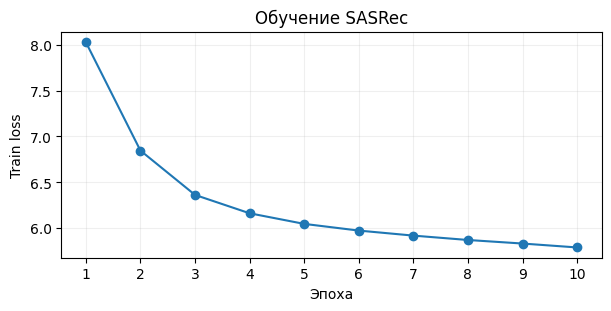

In [ ]:
retrieval_train = positives.loc[positives.timestamp < split.train_end]
retrieval_cfg = {
    **S5_CFG,
    'epochs': RETRIEVAL_EPOCHS,
}
print(f'Пользователей в периоде обучения SASRec: {retrieval_train.uid.nunique():,}', flush=True)
print(retrieval_cfg, flush=True)
source = Sources.fit_quick(
    retrieval_train, retrieval_cfg, device, negatives='inbatch_logq', seed=SEED, verbose=True,
)
source.meta['split'] = {'TRAIN_END': split.train_end}
source.save(root / 'sasrec')
print(f'Треков в каталоге: {source.n_items:,}')
sasrec_loss = source.history['inbatch_logq']
sasrec_epochs = range(1, len(sasrec_loss) + 1)
fig, ax = plt.subplots(figsize=(6, 3), layout='constrained')
ax.plot(sasrec_epochs, sasrec_loss, marker='o')
ax.set(xlabel='Эпоха', ylabel='Train loss', title='Обучение SASRec', xticks=list(sasrec_epochs))
ax.grid(alpha=0.2)
plt.show()
del retrieval_train

### 1.3. Признаки для ранкера

Одна строка — пара `(пользователь, кандидат)` за день. Используем скор и ранг источника, статистики трека и пользователя, историю повторов, артиста и сходство с прошлым. Позитивы вне пула ранкер восстановить не может.

In [ ]:
ITEM_HASH_BUCKETS = 200_003


ITEM_FEATURES = ['item_cnt_1d', 'item_cnt_7d', 'item_cnt_30d', 'item_full_share', 'item_like_rate_30d', 'item_age_days']


USER_FEATURES = ['user_cnt_1d', 'user_cnt_7d', 'user_cnt_30d', 'user_hist_len', 'user_n_artists_30d',
                 'user_like_rate_30d']


CROSS_FEATURES = ['ui_cnt', 'ui_last_dt_hours', 'ua_cnt_30d', 'ua_share_30d', 'ui_liked_before']


SOURCE_FEATURES = ([f'rank_{s}' for s in SOURCE_NAMES] + [f'score_{s}' for s in SOURCE_NAMES]
                   + [f'from_{s}' for s in SOURCE_NAMES])


NUM_FEATURES = ITEM_FEATURES + USER_FEATURES + CROSS_FEATURES + SOURCE_FEATURES


COUNT_FEATURES = ['item_cnt_1d', 'item_cnt_7d', 'item_cnt_30d', 'user_cnt_1d', 'user_cnt_7d', 'user_cnt_30d',
                  'user_hist_len', 'user_n_artists_30d', 'ui_cnt', 'ua_cnt_30d']   # тяжёлые хвосты -> log1p


@dataclass
class SliceData:
    T: int
    users: np.ndarray        # [U]
    cands: np.ndarray        # [U, k] исходные item_id, 0 — пусто
    X_num: pd.DataFrame      # [U*k, F], колонки NUM_FEATURES
    item_idx: np.ndarray     # [U*k] хэш item_id, 0 — пусто
    artist_idx: np.ndarray   # [U*k] индекс артиста, 0 — неизвестен
    listen: np.ndarray       # [U, k]
    like: np.ndarray         # [U, k]
    n_listen: np.ndarray     # [U] таргеты дня, включая не попавших в кандидаты
    n_like: np.ndarray       # [U]
    group: np.ndarray        # [U*k] номер пользователя внутри среза


def build_artist_index(mapping, catalog_item_ids):
    """item_id -> индекс первого (минимального) артиста трека, 1..A; словарь — по трекам каталога."""
    m = mapping[mapping.item_id.isin(catalog_item_ids)]
    first = m.groupby(m.item_id.astype(np.int64)).artist_id.min()
    arts = np.sort(first.unique())
    return pd.Series(np.searchsorted(arts, first.to_numpy()) + 1, index=first.index, name='artist_idx').astype(np.int64)


def _artist_of(item_ids, artist_index):
    item_ids = np.asarray(item_ids, dtype=np.int64)
    if artist_index is None:
        return np.zeros(len(item_ids), np.int64)
    return artist_index.reindex(item_ids).fillna(0).to_numpy().astype(np.int64)


def _by_pair(stats, uids, items):
    # значения stats (индекс — пара uid, ключ) в порядке переданных пар; нет пары — NaN
    key = pd.DataFrame({'uid': np.asarray(uids, np.int64), 'key': np.asarray(items, np.int64)})
    out = key.merge(stats.reset_index(), on=['uid', 'key'], how='left')
    assert len(out) == len(key) and (out.key.to_numpy() == key.key.to_numpy()).all()
    return out.drop(columns=['uid', 'key'])


def _ratio(a, b):
    with np.errstate(invalid='ignore', divide='ignore'):
        return np.where(b > 0, a / np.where(b > 0, b, 1), np.nan)         # нет знаменателя — NaN


def pair_counters(hist, users, cands, cutoff, likes_hist=None, artist_index=None, day=86_400):
    """Кроссы пользователь × трек и пользователь × артист по истории до отсечки; строки в порядке cands.ravel()."""
    users, cands = np.asarray(users), np.asarray(cands)
    uids, items = np.repeat(users, cands.shape[1]), cands.ravel().astype(np.int64)
    h = hist[hist.uid.isin(users)]
    h = pd.DataFrame({'uid': h.uid.to_numpy(np.int64), 'key': h.item_id.to_numpy(np.int64), 'ts': h.timestamp.to_numpy()})
    ui = _by_pair(h.groupby(['uid', 'key']).ts.agg(['size', 'max']), uids, items)
    f = pd.DataFrame({'ui_cnt': ui['size'].fillna(0).to_numpy(),
                      'ui_last_dt_hours': (cutoff - ui['max'].to_numpy()) / 3600})   # не слушал — NaN
    h30 = h[h.ts >= cutoff - 30 * day].assign(key=lambda d: _artist_of(d.key, artist_index))
    cand_art = _artist_of(items, artist_index)
    ua = _by_pair(h30[h30.key > 0].groupby(['uid', 'key']).size().rename('n'), uids, cand_art)
    f['ua_cnt_30d'] = np.where(cand_art > 0, ua.n.fillna(0).to_numpy(), 0)
    total = h30.groupby('uid').size().reindex(uids).to_numpy()
    with np.errstate(invalid='ignore', divide='ignore'):
        f['ua_share_30d'] = f.ua_cnt_30d.to_numpy() / total                  # нет истории за 30 дней — NaN
    if likes_hist is None:
        f['ui_liked_before'] = 0
    else:
        lk = likes_hist[likes_hist.uid.isin(users)]
        lk = pd.DataFrame({'uid': lk.uid.to_numpy(np.int64), 'key': lk.item_id.to_numpy(np.int64)})
        liked = _by_pair(lk.drop_duplicates().assign(v=1).set_index(['uid', 'key']).v, uids, items)
        f['ui_liked_before'] = liked.v.fillna(0).to_numpy()
    return f[CROSS_FEATURES]


def item_features(listens_hist, likes_hist, items, cutoff, day=86_400):
    items = np.asarray(items, np.int64)
    uniq = pd.unique(items[items > 0])
    lh = listens_hist[listens_hist.item_id.isin(uniq)]
    iid, ts = lh.item_id.to_numpy(np.int64), lh.timestamp.to_numpy()
    f = pd.DataFrame(index=pd.Index(uniq, dtype=np.int64))
    for w in (1, 7, 30):
        f[f'item_cnt_{w}d'] = pd.Series(ts >= cutoff - w * day).groupby(iid).sum()
    m30 = ts >= cutoff - 30 * day
    f['full'] = pd.Series((lh.played_ratio_pct.to_numpy() >= 95) & m30).groupby(iid).sum()
    lk = likes_hist[likes_hist.item_id.isin(uniq) & (likes_hist.timestamp >= cutoff - 30 * day)]
    f['likes'] = lk.groupby(lk.item_id.to_numpy(np.int64)).size()
    f['first'] = pd.Series(ts).groupby(iid).min()
    f = f.fillna({c: 0 for c in ['item_cnt_1d', 'item_cnt_7d', 'item_cnt_30d', 'full', 'likes']})
    f['item_full_share'] = _ratio(f.full.to_numpy(), f.item_cnt_30d.to_numpy())
    f['item_like_rate_30d'] = _ratio(f.likes.to_numpy(), f.item_cnt_30d.to_numpy())
    f['item_age_days'] = (cutoff - f['first']) / day                        # не встречался в истории — NaN
    out = f[ITEM_FEATURES].reindex(items).reset_index(drop=True)
    out[ITEM_FEATURES[:3]] = out[ITEM_FEATURES[:3]].fillna(0)               # пустой слот
    return out


def user_features(listens_hist, pos_hist, likes_hist, users, cutoff, artist_index=None, day=86_400):
    users = np.asarray(users, np.int64)
    idx = pd.Index(users)
    lh = listens_hist[listens_hist.uid.isin(users) & (listens_hist.timestamp >= cutoff - 30 * day)]
    uid, ts = lh.uid.to_numpy(np.int64), lh.timestamp.to_numpy()
    f = pd.DataFrame(index=idx)
    for w in (1, 7, 30):
        f[f'user_cnt_{w}d'] = pd.Series(ts >= cutoff - w * day).groupby(uid).sum()
    ph = pos_hist[pos_hist.uid.isin(users)]
    f['user_hist_len'] = ph.groupby(ph.uid.to_numpy(np.int64)).size()
    p30 = ph[ph.timestamp >= cutoff - 30 * day]
    a = pd.DataFrame({'uid': p30.uid.to_numpy(np.int64), 'a': _artist_of(p30.item_id, artist_index)})
    f['user_n_artists_30d'] = a[a.a > 0].groupby('uid').a.nunique()
    lk = likes_hist[likes_hist.uid.isin(users) & (likes_hist.timestamp >= cutoff - 30 * day)]
    f['likes'] = lk.groupby(lk.uid.to_numpy(np.int64)).size()
    f = f.fillna(0)
    f['user_like_rate_30d'] = _ratio(f.likes.to_numpy(), f.user_cnt_30d.to_numpy())
    return f[USER_FEATURES]


def _n_targets(day_df, users):
    # уникальные пары (пользователь, трек) дня — так же, как в make_labels
    d = day_df.drop_duplicates(['uid', 'item_id'])
    return d.groupby(d.uid.to_numpy(np.int64)).size().reindex(np.asarray(users, np.int64)).fillna(0).to_numpy(np.int64)


def _day_events(T, listens, likes, split):
    # события дня среза: listen — органические дослушанные, like — все лайки
    lis_day = events_of_day(listens, T, split)
    return lis_day[(lis_day.played_ratio_pct >= 50) & (lis_day.is_organic == 1)], events_of_day(likes, T, split)


def _slice_users(users, lis_day, hist_pos):
    if users is None:                                                     # есть listen в дне и история до отсечки
        users = np.intersect1d(lis_day.uid.unique(), hist_pos.uid.unique())
    return np.asarray(users)


def _pair_keys(uids, items):
    # пара (пользователь, трек) -> одно число: uid в старших 32 битах, item_id в младших
    return (np.asarray(uids).astype(np.int64) << 32) | np.asarray(items).astype(np.int64)


def make_labels(listens_day, likes_day, users, cands):
    # cands в исходных item_id (0 — пустой слот); listen — только органические дослушанные
    lis = listens_day[(listens_day.played_ratio_pct >= 50) & (listens_day.is_organic == 1)]
    cands = np.asarray(cands)
    key = _pair_keys(np.repeat(np.asarray(users), cands.shape[1]), cands.ravel())
    real = cands.ravel() > 0

    def hit(df):
        return (np.isin(key, _pair_keys(df.uid.to_numpy(), df.item_id.to_numpy())) & real).reshape(cands.shape).astype(np.int8)
    return hit(lis), hit(likes_day)


def build_slice(T, pos, listens, likes, sources, split, users=None, k=300, n_popular=None, artist_index=None,
                _check_history_only=False):
    """Срез T: кандидаты (k мест, из них n_popular — популярному), признаки на момент cutoff(T) и метки дня [T, T + day)."""
    if n_popular is None:
        raise ValueError('build_slice: нужен n_popular — сколько из k мест отдать популярному')
    if artist_index is None:                                              # иначе артистовые признаки молча стали бы нулями
        raise ValueError('build_slice: нужен artist_index (build_artist_index), без него артистовые признаки пустые')
    if _check_history_only:                                               # проверка самого ассерта: история без зазора
        hists = [d[d.timestamp < T] for d in (pos, listens, likes)]
    else:
        hists = [events_before(d, T, split) for d in (pos, listens, likes)]
    for h in hists:
        assert_no_leak(h, T, split)
    if _check_history_only:
        return None
    hist_pos, hist_lis, hist_lk = hists
    cutoff, day = split.cutoff(T), split.day

    lis_day, like_day = _day_events(T, listens, likes, split)
    users = _slice_users(users, lis_day, hist_pos)
    U = len(users)

    hp = hist_pos[hist_pos.uid.isin(users)]
    cands, feats = sources.candidates(hp, users, k, n_popular)
    flat = cands.ravel()
    assert (feats.item_id.to_numpy() == flat).all() and (feats.uid.to_numpy() == np.repeat(users, k)).all()

    X = pd.concat([item_features(hist_lis, hist_lk, flat, cutoff, day),
                   user_features(hist_lis, hp, hist_lk, users, cutoff, artist_index, day)
                   .reindex(np.repeat(users, k).astype(np.int64)).reset_index(drop=True),
                   pair_counters(hp, users, cands, cutoff, hist_lk, artist_index, day),
                   feats[SOURCE_FEATURES].reset_index(drop=True)], axis=1)[NUM_FEATURES].astype(np.float32)
    L, K = make_labels(lis_day, like_day, users, cands)
    return SliceData(T=T, users=users, cands=cands, X_num=X,
                     item_idx=np.where(flat > 0, flat % ITEM_HASH_BUCKETS + 1, 0).astype(np.int64),
                     artist_idx=_artist_of(flat, artist_index), listen=L, like=K,
                     n_listen=_n_targets(lis_day, users), n_like=_n_targets(like_day, users),
                     group=np.repeat(np.arange(U), k))

In [ ]:
mapping_path = data / 'artist_item_mapping.parquet'
if not mapping_path.exists():
    hf_hub_download('yandex/yambda', mapping_path.name, repo_type='dataset', local_dir=data)
artists = build_artist_index(pd.read_parquet(mapping_path), source.catalog)
days = []
for start in split.slice_starts():
    day = build_slice(start, positives, listens, likes, source, split,
                         k=K, n_popular=N_POPULAR, artist_index=artists)
    days.append(day)
    print(f'Срез {len(days)}/8: {len(day.users):,} пользователей', flush=True)
train, val, test = days[:6], days[6], days[7]

columns = ['score_Две башни', 'item_cnt_7d', 'ui_cnt', 'ui_last_dt_hours']
first_day = next(day for day in train if day.listen.any())
group = int(np.flatnonzero(first_day.listen.any(axis=1))[0])
positive_positions = np.flatnonzero(first_day.listen[group])
other_positions = np.flatnonzero((first_day.listen[group] == 0) & (first_day.cands[group] > 0))
positions = np.r_[positive_positions[:2], other_positions[:3]]
example = first_day.X_num.iloc[group * K + positions][columns].assign(
    пользователь=first_day.users[group], трек=first_day.cands[group, positions],
    метка=first_day.listen[group, positions],
).reset_index(drop=True)
display(example)

artist_item_mapping.parquet: reconstructing file:   0%|          |  0.00B / 38.3MB            

artist_item_mapping.parquet: downloading bytes:           |  0.00B            

Срез 1/8: 3,201 пользователей
Срез 2/8: 3,147 пользователей
Срез 3/8: 3,088 пользователей
Срез 4/8: 2,963 пользователей
Срез 5/8: 3,131 пользователей
Срез 6/8: 3,167 пользователей
Срез 7/8: 3,236 пользователей
Срез 8/8: 3,238 пользователей


,score_Две башни,item_cnt_7d,ui_cnt,ui_last_dt_hours,пользователь,трек,метка
0,14.652073,73.0,2.0,2427.102783,200,3584767,1
1,14.379560,300.0,0.0,NaN,200,7930756,1
2,15.188325,82.0,1.0,2427.104248,200,1078411,0
3,15.084872,48.0,2.0,391.879181,200,4655959,0
4,15.015532,127.0,2.0,2427.756836,200,2407600,0


### 1.4. Исторические признаки

Считаем повторы за 1/3/7/30 дней, давность последнего прослушивания, интервалы, интерес к артисту и сходство с историей длины 64. Числа нормируем по `log1p` и квантилям train. Отсутствующую давность отмечаем отдельным флагом.

In [ ]:
FEATURES = [
    'pair_count_1d', 'pair_count_3d', 'pair_count_7d', 'pair_count_30d',
    'pair_organic_count_7d', 'pair_organic_recency_hours', 'pair_prev_gap_hours',
    'pair_play_ratio_mean', 'pair_n_active_days_30d',
    'history_cosine_last', 'history_cosine_max', 'history_cosine_mean',
    'history_cosine_decay', 'artist_cosine_recent_match',
]


def history_features(d, pos, source, split, *, max_history=32):
    cutoff = split.cutoff(d.T)
    history = events_before(pos[pos.uid.isin(d.users)], d.T, split)
    assert_no_leak(history, d.T, split)
    sorted_history = _sort_history(history)
    pair = sorted_history.groupby(['uid', 'item_id'], sort=False)
    last = pair.timestamp.agg(['size', 'max'])
    lookup = pd.MultiIndex.from_arrays([np.repeat(d.users, d.cands.shape[1]), d.cands.ravel()], names=['uid','item_id'])
    data = {}
    for days in (1,3,7,30):
        recent = history[history.timestamp >= cutoff-days*split.day]
        data[f'pair_count_{days}d'] = recent.groupby(['uid','item_id'], sort=False).size().reindex(lookup, fill_value=0).to_numpy()
    organic = history[history.is_organic == 1]
    organic_recent = organic[organic.timestamp >= cutoff-7*split.day]
    data['pair_organic_count_7d'] = organic_recent.groupby(['uid','item_id'], sort=False).size().reindex(lookup,fill_value=0).to_numpy()
    data['pair_organic_recency_hours'] = (cutoff-organic.groupby(['uid','item_id'], sort=False).timestamp.max().reindex(lookup).to_numpy())/3600
    prev = sorted_history.loc[pair.cumcount(ascending=False)==1].set_index(['uid','item_id']).timestamp
    data['pair_prev_gap_hours'] = (last['max']-prev).reindex(lookup).to_numpy()/3600
    data['pair_play_ratio_mean'] = pair.played_ratio_pct.mean().reindex(lookup).to_numpy()
    active = history[history.timestamp >= cutoff-30*split.day].assign(active_day=lambda h: (cutoff-h.timestamp-1)//split.day)
    data['pair_n_active_days_30d'] = active.groupby(['uid','item_id'], sort=False).active_day.nunique().reindex(lookup,fill_value=0).to_numpy()

    candidate_idx = source.item2idx.reindex(d.cands.ravel()).fillna(0).to_numpy(np.int32).reshape(d.cands.shape)
    recent = sorted_history.groupby('uid',sort=False).tail(max_history)
    recent = recent.assign(idx=recent.item_id.map(source.item2idx).fillna(0).astype(np.int32),
                           age=(cutoff-recent.timestamp)/3600)
    groups = {int(u): np.asarray(g[['idx','age']]) for u,g in recent.groupby('uid',sort=False)}
    hist_idx = np.zeros((len(d.users),max_history), np.int32)
    hist_age = np.zeros_like(hist_idx, dtype=np.float32)
    for i,u in enumerate(d.users):
        events = groups.get(int(u))
        if events is not None:
            hist_idx[i,-len(events):], hist_age[i,-len(events):] = events.T
    embeddings = item_vectors(source.tt_model)
    norm = np.linalg.norm(embeddings, axis=1)
    embeddings = embeddings/np.maximum(norm[:,None],1e-8)
    out = np.zeros((*d.cands.shape,5),np.float32)
    arts = d.artist_idx.reshape(d.cands.shape)
    catalog_arts = source.history.get('experiment_catalog_artists')
    for i in range(0,len(d.users),64):
        end=i+64
        c = candidate_idx[i:end]
        h = hist_idx[i:end]
        hm = h>0
        sims = embeddings[c] @ np.swapaxes(embeddings[h],1,2)
        distinct = (c[:,:,None]!=h[:,None,:]) & hm[:,None,:]
        count = distinct.sum(2)
        out[i:end,:,0] = np.where(hm[:,-1,None],sims[:,:,-1],0)
        out[i:end,:,1] = np.where(count>0,np.where(distinct,sims,-1).max(2),0)
        out[i:end,:,2] = np.where(distinct,sims,0).sum(2)/np.maximum(count,1)
        decay = np.exp(-hist_age[i:end,None,:]/48)*distinct
        out[i:end,:,3] = (sims*decay).sum(2)/np.maximum(decay.sum(2),1e-6)
        if catalog_arts is not None:
            ca = arts[i:end]
            ha = catalog_arts[h]
            same = (ca[:,:,None]==ha[:,None,:]) & (ca[:,:,None]>0) & distinct
            out[i:end,:,4] = (same*np.exp(-hist_age[i:end,None,:]/48)).sum(2)
    for n, name in enumerate(FEATURES[-5:]):
        data[name] = out[:,:,n].ravel()
    return pd.DataFrame(data, columns=FEATURES, dtype=np.float32)

In [ ]:
class NumericNormalizer:
    """log1p для счётчиков, затем квантильное преобразование по 64 квантилям train в [-1, 1].
    Пропуск -> 0 (середина шкалы) плюс бинарный флаг для каждого признака, у которого в train есть NaN."""

    def __init__(self, n_quantiles=64):
        self.n_quantiles = n_quantiles

    def _prep(self, X):
        if isinstance(X, pd.DataFrame) and list(X.columns) != NUM_FEATURES:
            raise ValueError('колонки X не совпадают с NUM_FEATURES (состав или порядок)')
        X = np.asarray(X, dtype=np.float64)
        assert X.ndim == 2 and X.shape[1] == len(NUM_FEATURES), 'ожидаются колонки NUM_FEATURES'
        X = X.copy()
        X[:, self._count] = np.log1p(np.maximum(X[:, self._count], 0))
        return X

    def fit(self, X_num_train):
        self._count = [NUM_FEATURES.index(c) for c in COUNT_FEATURES]
        X = self._prep(X_num_train)
        probs = np.linspace(0, 1, self.n_quantiles)
        self.knots = []
        for j in range(X.shape[1]):
            x = X[~np.isnan(X[:, j]), j]
            if len(x) == 0:                                                # признак целиком пустой
                self.knots.append((np.zeros(1), np.full(1, 0.5))); continue
            xp, inv = np.unique(np.quantile(x, probs), return_inverse=True)
            self.knots.append((xp, np.bincount(inv, probs) / np.bincount(inv)))   # совпавшие квантили — средний уровень
        self.flag_cols = [j for j in range(X.shape[1]) if np.isnan(X[:, j]).any()]
        self.n_out = X.shape[1] + len(self.flag_cols)
        return self

    def transform(self, X):
        X = self._prep(X)
        n_feat = X.shape[1]
        out = np.zeros((len(X), self.n_out), np.float32)
        for j, (xp, p) in enumerate(self.knots):
            miss = np.isnan(X[:, j])
            z = 2 * np.interp(np.where(miss, xp[0], X[:, j]), xp, p) - 1
            out[:, j] = np.where(miss, 0.0, z)
        for t, j in enumerate(self.flag_cols):
            out[:, n_feat + t] = np.isnan(X[:, j])
        return out


class HistoryNormalizer:
    """Use the original normalizer for the baseline features and training quantiles for new features."""
    def __init__(self, base, extra_train):
        self.base = base
        self.knots = []
        q = np.linspace(0, 1, 96)
        for column in extra_train:
            values = extra_train[column].dropna().to_numpy()
            if len(values):
                bins, reverse = np.unique(np.quantile(values, q), return_inverse=True)
                self.knots.append((bins, np.bincount(reverse, q) / np.bincount(reverse)))
            else:
                self.knots.append((np.array([0]), np.array([0.5])))
        self.n_out = base.n_out + 2 * len(self.knots)

    def transform(self, frame):
        n_base = len(NUM_FEATURES)
        extra = frame.iloc[:, n_base:].to_numpy(np.float32)
        result = np.empty((len(frame), self.n_out), dtype=np.float32)
        result[:, :self.base.n_out] = self.base.transform(frame.iloc[:, :n_base])
        for i, (bins, ranks) in enumerate(self.knots):
            col = extra[:, i]
            missing = ~np.isfinite(col)
            result[:, self.base.n_out + i] = np.where(missing, 0, 2 * np.interp(col, bins, ranks) - 1)
            result[:, self.base.n_out + len(self.knots) + i] = missing
        return result

In [ ]:
source.history['experiment_catalog_artists'] = _artist_of(source.catalog_ext, artists)
for i, day in enumerate(days):
    days[i] = replace(day, X_num=pd.concat([
        day.X_num, history_features(day, positives, source, split, max_history=HISTORY_LENGTH)
    ], axis=1, copy=False))
    print(f'Признаки истории, срез {i + 1}/{len(days)}', flush=True)
train, val, test = days[:6], days[6], days[7]
del day
train_sample = pd.concat([
    day.X_num.sample(n=min(len(day.X_num), 150_000), random_state=SEED)
    for day in train
], ignore_index=True)
numeric = NumericNormalizer().fit(train_sample[NUM_FEATURES])
extra_cols = train_sample.columns[len(NUM_FEATURES):]
normalizer = HistoryNormalizer(numeric, train_sample[extra_cols])

Признаки истории, срез 1/8
Признаки истории, срез 2/8
Признаки истории, срез 3/8
Признаки истории, срез 4/8
Признаки истории, срез 5/8
Признаки истории, срез 6/8
Признаки истории, срез 7/8
Признаки истории, срез 8/8


,медиана,p99,максимум,доля пропусков
item_cnt_7d,53.000000,1056.000000,2348.000000,0.00
ui_cnt,0.000000,29.000000,4257.000000,0.00
ui_last_dt_hours,852.948975,6688.940918,7147.498047,0.72


,сколько раз пользователь слушал трек,после преобразования
0,0.0,-0.285714
1,132.0,0.978924
2,4257.0,1.000000


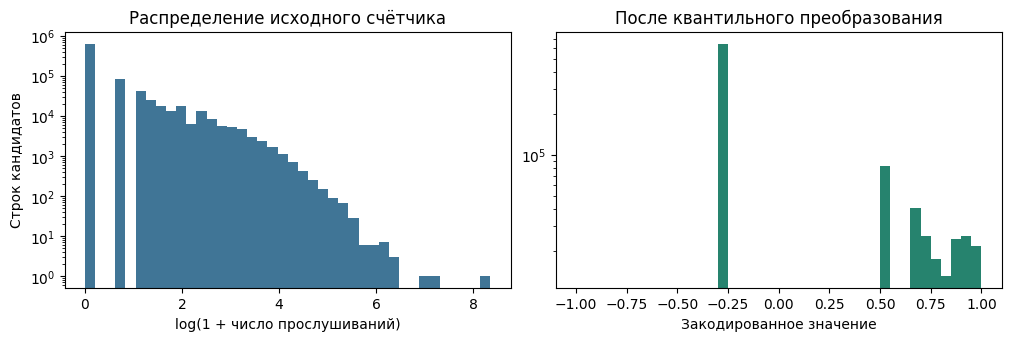

In [ ]:
columns = ['item_cnt_7d', 'ui_cnt', 'ui_last_dt_hours']
observed = train_sample[columns]
summary = observed.quantile([0.5, 0.99, 1.0]).T
summary.columns = ['медиана', 'p99', 'максимум']
summary['доля пропусков'] = observed.isna().mean()
display(summary.round(3))

j = NUM_FEATURES.index('ui_cnt')
examples = observed['ui_cnt'].drop_duplicates().sort_values()
example_rows = train_sample.loc[examples.iloc[[0, len(examples) // 2, -1]].index, NUM_FEATURES]
display(pd.DataFrame({
    'сколько раз пользователь слушал трек': example_rows['ui_cnt'].to_numpy(),
    'после преобразования': numeric.transform(example_rows)[:, j],
}))
raw_counts = observed['ui_cnt'].to_numpy()
encoded_counts = numeric.transform(train_sample[NUM_FEATURES])[:, j]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), layout='constrained')
axes[0].hist(np.log1p(raw_counts), bins=40, color='#407596', log=True)
axes[0].set(xlabel='log(1 + число прослушиваний)', ylabel='Строк кандидатов',
            title='Распределение исходного счётчика')
axes[1].hist(encoded_counts, bins=np.linspace(-1, 1, 41), color='#26836e', log=True)
axes[1].set(xlabel='Закодированное значение', title='После квантильного преобразования')
plt.show()

### 1.5. MLP и CatBoost

MLP: listwise softmax по кандидатам группы, все позитивы и не более 56 негативов. CatBoost: PairLogit, до 100 негативов на группу. Лучшие эпоху и число деревьев выбираем **только по val**.

In [ ]:
class FeatureEncoder(nn.Module):
    def __init__(self, n_num, item_buckets, n_artists, d_item=32, d_artist=16):
        # n_artists = A, число артистов в build_artist_index (индексы 1..A); +1 — строка под 0
        # d_item = 0 — без эмбеддинга трека: item в forward принимается и игнорируется
        super().__init__()
        self.item_emb = nn.Embedding(item_buckets + 1, d_item, padding_idx=0) if d_item > 0 else None   # 0 — пустой слот
        self.artist_emb = nn.Embedding(n_artists + 1, d_artist, padding_idx=0)      # 0 — артист неизвестен
        self.d_out = n_num + d_item + d_artist

    def forward(self, num, item, artist):
        parts = [self.artist_emb(artist), num]
        if self.item_emb is not None:
            parts.insert(0, self.item_emb(item))
        return torch.cat(parts, dim=1)


@torch.no_grad()
def _logits(model, encoder, num, item, artist, device, batch=8192):
    was = (model.training, encoder.training)
    model.eval(); encoder.eval()
    out = [model(encoder(num[b:b + batch].to(device), item[b:b + batch].to(device), artist[b:b + batch].to(device))).cpu()
           for b in range(0, len(num), batch)]
    model.train(was[0]); encoder.train(was[1])
    return torch.cat(out).numpy().astype(np.float64)


def predict_torch(model, encoder, d, normalizer, head=0):
    U, k = d.cands.shape
    device = next(model.parameters()).device
    num = torch.as_tensor(normalizer.transform(d.X_num))
    z = _logits(model, encoder, num, torch.as_tensor(d.item_idx), torch.as_tensor(d.artist_idx), device)[:, head]
    return np.where(d.cands > 0, z.reshape(U, k), -np.inf)                 # пустые слоты вниз


def _top_k_labels(scores, labels, k):
    # метки в порядке убывания скора; ничьи — по порядку колонок
    order = np.argsort(-scores, axis=1, kind='stable')[:, :k]
    return np.take_along_axis(labels, order, axis=1)


def ndcg_at_k(scores, labels, k=10):
    top = _top_k_labels(scores, labels, k).astype(np.float64)
    disc = 1.0 / np.log2(np.arange(2, top.shape[1] + 2))
    dcg = (top * disc).sum(1)
    n_pos = np.minimum((labels > 0).sum(1), top.shape[1])       # идеал — все позитивы кандидатов сверху
    idcg = np.cumsum(disc)[np.maximum(n_pos, 1) - 1]
    return float(np.where(n_pos > 0, dcg / idcg, 0.0).mean())   # без позитивов — 0, но в среднем остаются


class PiecewiseRanker(torch.nn.Module):
    """A hinge basis on quantile-normalized numeric inputs and residual MLP."""
    def __init__(self, d_in, n_numeric):
        super().__init__()
        self.n_numeric = n_numeric
        self.register_buffer('knots', torch.linspace(-0.85, 0.85, 12))
        self.additive = torch.nn.Linear(n_numeric * 13, 1)
        self.mlp = torch.nn.Sequential(
            torch.nn.Linear(n_numeric * 13 + d_in - n_numeric, 192),
            torch.nn.LayerNorm(192), torch.nn.GELU(), torch.nn.Dropout(0.10),
            torch.nn.Linear(192, 96), torch.nn.LayerNorm(96), torch.nn.GELU(),
            torch.nn.Dropout(0.10), torch.nn.Linear(96, 1),
        )

    def forward(self, x):
        # FeatureEncoder puts category embeddings before numeric features.
        n_categorical = x.shape[1] - self.n_numeric
        z = x[:, n_categorical:]
        basis = torch.cat([z, F.relu(z[..., None] - self.knots).flatten(1)], dim=1)
        return self.additive(basis) + self.mlp(torch.cat([basis, x[:, :n_categorical]], dim=1))


def group_loss(logits, labels, valid, kind):
    positive = (labels > 0) & valid
    negative = (labels == 0) & valid
    if kind == 'bce':
        return (F.binary_cross_entropy_with_logits(logits, labels.float(), reduction='none') * valid).sum() / valid.sum().clamp_min(1)
    if kind == 'listwise':
        log_denom = logits.masked_fill(~valid, -1e9).logsumexp(dim=1)
        log_positive = (logits * positive).sum(1) / positive.sum(1).clamp_min(1)
        active = positive.any(1)
        return ((log_denom - log_positive) * active).sum() / active.sum().clamp_min(1)

    pairs = positive[:, :, None] & negative[:, None, :]
    losses = F.softplus(logits[:, None, :] - logits[:, :, None])
    if kind == 'lambda':
        order = logits.detach().masked_fill(~valid, -torch.inf).argsort(dim=1, descending=True, stable=True)
        ranks = order.argsort(dim=1) + 1
        discounts = torch.where(ranks <= 10, 1.0 / torch.log2(ranks + 1.0), 0.0)
        ideal = (1.0 / torch.log2(torch.arange(2, 12, device=logits.device, dtype=logits.dtype))).cumsum(0)
        idcg = ideal[(positive.sum(1) - 1).clamp(0, 9)]
        delta = (discounts[:, :, None] - discounts[:, None, :]).abs()
        weights = pairs * delta / idcg[:, None, None]
    elif kind == 'pairwise':
        weights = pairs
    else:
        raise ValueError(f'Неизвестный лосс: {kind}')
    return (weights * losses).sum() / weights.sum().clamp_min(1)


def grouped_inputs(train, norm):
    labels = np.concatenate([d.listen for d in train])
    candidates = np.concatenate([d.cands for d in train])
    keep = (labels > 0).any(1)
    labels, candidates = labels[keep], candidates[keep]
    nums = np.concatenate([norm.transform(d.X_num).reshape(*d.cands.shape, norm.n_out) for d in train])[keep]
    artists = np.concatenate([d.artist_idx.reshape(d.cands.shape) for d in train])[keep]
    return tuple(torch.as_tensor(x) for x in (nums, artists, labels, candidates > 0))


def fit_grouped(train, val, norm, make_model, *, kind, seed=42, epochs=10, device='cpu',
                inputs=None, batch_groups=64, negatives=64, d_artist=16, lr=0.001, n_artists=None):
    torch.manual_seed(seed)
    num, artist, y, valid = inputs if inputs is not None else grouped_inputs(train, norm)
    if n_artists is None:
        n_artists = max(int(d.artist_idx.max()) for d in [*train, val])
    encoder = FeatureEncoder(norm.n_out, ITEM_HASH_BUCKETS, n_artists, d_item=0, d_artist=d_artist).to(device)
    model = make_model(encoder.d_out).to(device)
    optimizer = torch.optim.AdamW([*model.parameters(), *encoder.parameters()], lr=lr, weight_decay=0.001)
    rng = torch.Generator().manual_seed(seed)
    if not len(y):
        raise ValueError("No training groups have a positive candidate")
    history, best_score, best_state = [], -1.0, None
    for epoch in range(1, epochs + 1):
        model.train()
        encoder.train()
        for group in torch.randperm(len(y), generator=rng).split(batch_groups):
            yy, vv = y[group], valid[group]
            positive = (yy > 0) & vv
            picks = min(negatives + int(positive.sum(1).max()), yy.shape[1])
            priority = torch.rand(yy.shape, generator=rng).masked_fill(~vv, -1)
            priority = priority + 2 * positive
            cols = priority.topk(picks, dim=1).indices
            selected_positive = positive.gather(1, cols)
            within_budget = (~selected_positive).cumsum(dim=1) <= negatives
            selected = vv.gather(1, cols) & (selected_positive | within_budget)
            rows = group[:, None]
            x = num[rows, cols].flatten(0, 1).to(device)
            a = artist[rows, cols].flatten().to(device)
            logits = model(encoder(x, a, a)).reshape(cols.shape)
            loss = group_loss(logits, yy.gather(1, cols).to(device), selected.to(device), kind)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
        scores = predict_torch(model, encoder, val, norm)
        metric = ndcg_at_k(scores, val.listen)
        history.append(metric)
        print(f'{kind}, seed={seed}, epoch={epoch}: val NDCG@10={metric:.6f}', flush=True)
        if metric > best_score:
            best_score = metric
            best_state = {
                'model': {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                'encoder': {k: v.detach().cpu().clone() for k, v in encoder.state_dict().items()},
            }
        elif epoch - (1 + int(np.argmax(history))) >= 2:
            break
    model.load_state_dict(best_state['model'])
    encoder.load_state_dict(best_state['encoder'])
    return model, encoder, history

In [ ]:
def fit_mlp(train, val, norm, factory, **settings):
    # Кодируем по небольшим блокам. Полная матрица хранится на диске.
    groups = [np.flatnonzero(day.listen.any(axis=1)) for day in train]
    n_groups, width = sum(map(len, groups)), train[0].cands.shape[1]
    if n_groups == 0:
        raise ValueError('В обучении нет групп с позитивом среди кандидатов')
    with TemporaryDirectory(dir=root) as scratch:
        numbers = np.memmap(Path(scratch) / 'train.bin', mode='w+', dtype=np.float32,
                            shape=(n_groups, width, norm.n_out))
        artists = np.empty((n_groups, width), dtype=np.int64)
        labels = np.empty((n_groups, width), dtype=np.int8)
        valid = np.empty((n_groups, width), dtype=bool)
        offset = 0
        for day, users in zip(train, groups):
            for start in range(0, len(users), 128):
                batch = users[start:start + 128]
                rows = (batch[:, None] * width + np.arange(width)).ravel()
                end = offset + len(batch)
                numbers[offset:end] = norm.transform(day.X_num.iloc[rows]).reshape(-1, width, norm.n_out)
                artists[offset:end] = day.artist_idx.reshape(day.cands.shape)[batch]
                labels[offset:end] = day.listen[batch]
                valid[offset:end] = day.cands[batch] > 0
                offset = end
        print(f'Обучающих групп с позитивом в пуле: {n_groups:,}', flush=True)
        inputs = tuple(torch.from_numpy(x) for x in (numbers, artists, labels, valid))
        result = fit_grouped(train, val, norm, factory, inputs=inputs, **settings)
        del inputs, numbers
    return result

In [ ]:
# Выбор эпохи по NDCG@10 на валидации. Тест остаётся отдельным.
ranker, encoder, curve = fit_mlp(
    train, val, normalizer, lambda n: PiecewiseRanker(n, normalizer.n_out),
    kind='listwise', seed=SEED, device=device, epochs=RANKER_EPOCHS,
    negatives=56, batch_groups=80, d_artist=8, n_artists=int(artists.max()),
)

Обучающих групп с позитивом в пуле: 13,756
listwise, seed=42, epoch=1: val NDCG@10=0.334374
listwise, seed=42, epoch=2: val NDCG@10=0.344328
listwise, seed=42, epoch=3: val NDCG@10=0.347545
listwise, seed=42, epoch=4: val NDCG@10=0.348201
listwise, seed=42, epoch=5: val NDCG@10=0.348438
listwise, seed=42, epoch=6: val NDCG@10=0.347189
listwise, seed=42, epoch=7: val NDCG@10=0.348479
listwise, seed=42, epoch=8: val NDCG@10=0.346384
listwise, seed=42, epoch=9: val NDCG@10=0.349594
listwise, seed=42, epoch=10: val NDCG@10=0.348311
listwise, seed=42, epoch=11: val NDCG@10=0.351925
listwise, seed=42, epoch=12: val NDCG@10=0.351968


In [ ]:
def _catboost_frame(d, rows=None):
    X = d.X_num.reset_index(drop=True)
    X = (X if rows is None else X.iloc[rows]).astype(np.float32)           # float32: на полных срезах — гигабайты
    X['artist_idx'] = d.artist_idx if rows is None else d.artist_idx[rows]  # категориальная колонка, числа те же
    return X.reset_index(drop=True)


def _catboost_pool(slices, label, offset=0, neg_per_group=None, seed=0):
    # group_id = (срез, пользователь): строки пользователя идут подряд, id сквозные по срезам
    from catboost import Pool
    rng = np.random.default_rng(seed)
    X, y, g = [], [], []
    for d in slices:
        lab, grp = getattr(d, label).ravel(), d.group
        keep = d.cands.ravel() > 0                                         # пустые слоты не кандидаты
        keep &= pd.Series(lab > 0).groupby(grp).transform('any').to_numpy()   # группа без позитива пар не даёт
        if neg_per_group is not None:                                      # все позитивы + до N случайных негативов группы
            r = pd.Series(np.where(keep & (lab == 0), rng.random(len(lab)), np.inf))
            keep &= (lab > 0) | (r.groupby(grp).rank(method='first').to_numpy() <= neg_per_group)
        rows = np.flatnonzero(keep)
        X.append(_catboost_frame(d, rows)); y.append(lab[rows]); g.append(grp[rows] + offset)
        offset += len(d.users)
    X, y, g = pd.concat(X, ignore_index=True), np.concatenate(y), np.concatenate(g)
    if len(y) == 0:
        raise ValueError('в срезах нет ни одной группы с позитивом: обучать и останавливать CatBoost не на чем')
    return Pool(X, y.astype(np.float32), group_id=g, cat_features=['artist_idx'])


def fit_catboost(train_slices, val_slice, label='listen', iterations=1000, task_type=None, loss_function='PairLogit',
                 neg_per_group=None, verbose=False):
    """neg_per_group — сколько негативов группы оставить в обучении (валидация полная): число пар PairLogit
    растёт как позитивы × негативы, и на полных срезах бустинг иначе не помещается в память."""
    from catboost import CatBoostRanker
    if task_type is None:                                                  # GPU, если есть CUDA, иначе CPU
        task_type = 'GPU' if torch.cuda.is_available() else 'CPU'
    train = _catboost_pool(train_slices, label, neg_per_group=neg_per_group)
    val = _catboost_pool([val_slice], label, offset=sum(len(d.users) for d in train_slices))
    model = CatBoostRanker(loss_function=loss_function, eval_metric='NDCG:top=10', iterations=iterations,
                           od_type='Iter', od_wait=50, use_best_model=True, task_type=task_type,
                           random_seed=0, verbose=verbose, allow_writing_files=False)
    return model.fit(train, eval_set=val)


def predict_catboost(model, d):
    U, k = d.cands.shape
    s = np.asarray(model.predict(_catboost_frame(d)), dtype=np.float64).reshape(U, k)
    return np.where(d.cands > 0, s, -np.inf)                               # пустые слоты вниз

Groupwise loss function. OneHotMaxSize set to 10


Default metric period is 5 because NDCG is/are not implemented for GPU
Metric NDCG:top=10;type=Base is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time


0:	test: 0.3164391	best: 0.3164391 (0)	total: 751ms	remaining: 12m 30s
25:	test: 0.4110086	best: 0.4116512 (23)	total: 6.55s	remaining: 4m 5s
50:	test: 0.4305712	best: 0.4305712 (50)	total: 11.9s	remaining: 3m 41s
75:	test: 0.4438488	best: 0.4438488 (75)	total: 17.8s	remaining: 3m 36s
100:	test: 0.4500421	best: 0.4501132 (99)	total: 23.1s	remaining: 3m 25s
125:	test: 0.4538708	best: 0.4538775 (123)	total: 29s	remaining: 3m 21s
150:	test: 0.4565736	best: 0.4565736 (150)	total: 34.3s	remaining: 3m 13s
175:	test: 0.4585567	best: 0.4586958 (172)	total: 39.8s	remaining: 3m 6s
200:	test: 0.4596849	best: 0.4597776 (199)	total: 45.3s	remaining: 3m
225:	test: 0.4603143	best: 0.4606195 (220)	total: 50.5s	remaining: 2m 52s
250:	test: 0.4605516	best: 0.4608263 (243)	total: 56.2s	remaining: 2m 47s
275:	test: 0.4619429	best: 0.4619429 (275)	total: 1m 1s	remaining: 2m 40s
300:	test: 0.4619350	best: 0.4622904 (287)	total: 1m 6s	remaining: 2m 35s
325:	test: 0.4629513	best: 0.4629513 (325)	total: 1m 12s

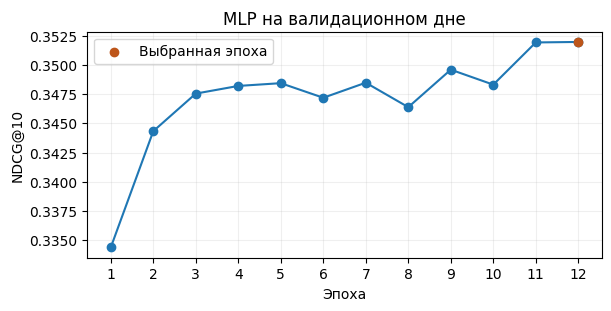

In [ ]:
catboost = fit_catboost(train, val, iterations=CATBOOST_ITERATIONS,
                          task_type='GPU' if device == 'cuda' else 'CPU',
                          neg_per_group=100, verbose=25)
print(f'Лучшая эпоха MLP: {1 + np.argmax(curve)}')
print(f'Деревьев CatBoost: {catboost.tree_count_}')
epochs = np.arange(1, len(curve) + 1)
best_epoch = int(np.argmax(curve))
fig, ax = plt.subplots(figsize=(6, 3), layout='constrained')
ax.plot(epochs, curve, marker='o')
ax.scatter(epochs[best_epoch], curve[best_epoch], color='#bd551a', zorder=3,
           label='Выбранная эпоха')
ax.set(xlabel='Эпоха', ylabel='NDCG@10', title='MLP на валидационном дне', xticks=epochs)
ax.legend()
ax.grid(alpha=0.2)
plt.show()

### 1.6. Оценка на общем пуле

Основные метрики: Recall пула, Recall@10 и NDCG@10. Сравнение ранкеров — на одинаковых кандидатах; интервалы разности NDCG@10 — парный бутстреп по пользователям.

In [ ]:
def start_scores(d):
    # стартовый порядок — скор «Двух башен» u·e, он есть у всех кандидатов; пустой слот (NaN) — вниз
    U, k = d.cands.shape
    s = d.X_num['score_Две башни'].to_numpy(np.float64).reshape(U, k)
    return np.where(np.isnan(s), -np.inf, s)


def recall_at_k(scores, labels, n_targets, k=10):
    n_targets = np.asarray(n_targets)
    ok = n_targets > 0
    if not ok.any():
        return float('nan')
    hits = _top_k_labels(scores, labels, k).sum(1)
    return float((hits[ok] / n_targets[ok]).mean())


def ceiling(labels, n_targets):
    # потолок источников: какая доля таргетов вообще попала в кандидаты
    n_targets = np.asarray(n_targets)
    ok = n_targets > 0
    if not ok.any():
        return float('nan')
    return float(((labels > 0).sum(1)[ok] / n_targets[ok]).mean())

Recall пула на тесте: 0.3221


,NDCG@10,Recall@10
"Пул, сортировка по скору SASRec",0.0944,0.0559
CatBoost / PairLogit,0.3390,0.1656
MLP / listwise,0.3430,0.1686


,"MLP минус CatBoost, NDCG@10",нижняя граница 95%,верхняя граница 95%,пользователей
0,0.00399,-0.00057,0.00851,3238


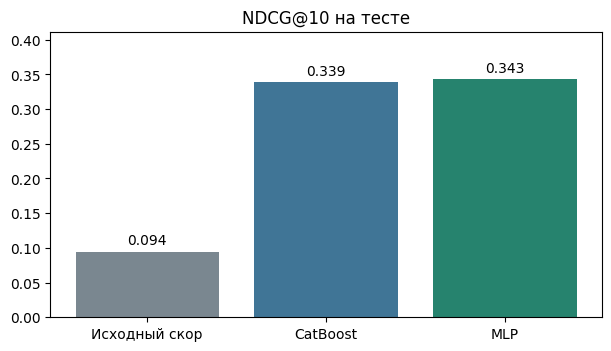

In [ ]:
retrieval_scores = start_scores(test)
mlp_scores = predict_torch(ranker, encoder, test, normalizer)
catboost_scores = predict_catboost(catboost, test)

def evaluate(scores):
    return {
        'NDCG@10': ndcg_at_k(scores, test.listen),
        'Recall@10': recall_at_k(scores, test.listen, test.n_listen),
    }

results = {
    'Пул, сортировка по скору SASRec': evaluate(retrieval_scores),
    'CatBoost / PairLogit': evaluate(catboost_scores),
    'MLP / listwise': evaluate(mlp_scores),
}
print(f'Recall пула на тесте: {ceiling(test.listen, test.n_listen):.4f}')
table = pd.DataFrame(results).T
table.to_csv(root / 'metrics.csv')
display(table.round(4))

def user_ndcg(scores):
    top_labels = _top_k_labels(scores, test.listen, 10)
    discounts = 1 / np.log2(np.arange(2, top_labels.shape[1] + 2))
    positive_count = np.minimum(test.listen.sum(axis=1), len(discounts))
    ideal_dcg = np.r_[1.0, np.cumsum(discounts)][positive_count]
    return (top_labels @ discounts) / ideal_dcg

ndcg_difference = user_ndcg(mlp_scores) - user_ndcg(catboost_scores)
rng = np.random.default_rng(SEED)
samples = [ndcg_difference[rng.integers(len(ndcg_difference), size=len(ndcg_difference))].mean()
           for _ in range(2_000)]
low, high = np.quantile(samples, [0.025, 0.975])
paired = pd.DataFrame([{
    'MLP минус CatBoost, NDCG@10': ndcg_difference.mean(),
    'нижняя граница 95%': low, 'верхняя граница 95%': high,
    'пользователей': len(ndcg_difference),
}])
paired.to_csv(root / 'paired_ndcg.csv', index=False)
display(paired.round(5))
labels = ['Исходный скор', 'CatBoost', 'MLP']
colors = ['#7a8790', '#407596', '#26836e']
fig, ax = plt.subplots(figsize=(6, 3.4), layout='constrained')
values = table['NDCG@10'].to_numpy()
bars = ax.bar(labels, values, color=colors)
ax.bar_label(bars, fmt='%.3f', padding=3)
ax.set(title='NDCG@10 на тесте', ylim=(0, max(0.01, values.max() * 1.2)))
plt.show()

**Итог ранжирования.** Recall пула = **0.3221**. NDCG@10: исходный скор SASRec — **0.0944**, CatBoost — **0.3390**, MLP — **0.3430**. Recall@10: **0.0559**, **0.1656**, **0.1686** соответственно.

MLP чуть выше CatBoost, но 95% ДИ разности NDCG@10 = **[−0.00057; 0.00851]** содержит ноль. На полном пуле Recall одинаковый — меняется только порядок.

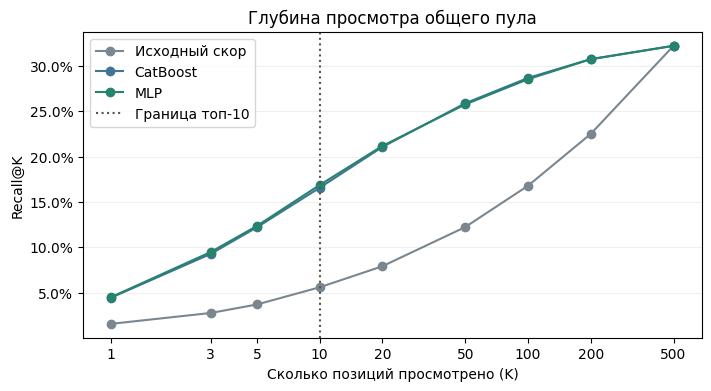

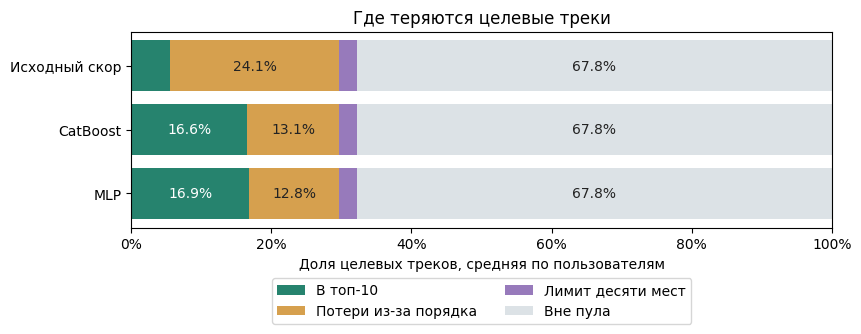

,В топ-10,Потери из-за порядка,Лимит десяти мест,Вне пула
Исходный скор,5.6%,24.1%,2.5%,67.8%
CatBoost,16.6%,13.1%,2.5%,67.8%
MLP,16.9%,12.8%,2.5%,67.8%


In [ ]:
from matplotlib.ticker import PercentFormatter

pool_size = test.cands.shape[1]
depths = sorted({k for k in (1, 3, 5, 10, 20, 50, 100, 200, pool_size) if k <= pool_size})
active = test.n_listen > 0
n_targets = test.n_listen[active]
pool_hits = test.listen[active].sum(axis=1)
recall_pool = (pool_hits / n_targets).mean()
oracle_at_10 = (np.minimum(10, pool_hits) / n_targets).mean()

# Одна сортировка на модель даёт Recall для всех глубин.
recall_curves = []
for scores in (retrieval_scores, catboost_scores, mlp_scores):
    ordered_labels = _top_k_labels(scores, test.listen, pool_size)[active]
    hits_by_depth = ordered_labels.cumsum(axis=1)[:, np.array(depths) - 1]
    recall_curves.append((hits_by_depth / n_targets[:, None]).mean(axis=0))

fig, ax = plt.subplots(figsize=(7, 3.8), layout='constrained')
for label, color, curve_at_k in zip(labels, colors, recall_curves):
    ax.plot(depths, curve_at_k, label=label, color=color, marker='o')
ax.axvline(10, ls=':', color='#555555', label='Граница топ-10')
ax.set(xscale='log', xlabel='Сколько позиций просмотрено (K)',
       ylabel='Recall@K', title='Глубина просмотра общего пула')
ax.set_xticks(depths, labels=[str(k) for k in depths])
ax.minorticks_off()
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(loc='best')
ax.grid(axis='y', alpha=0.2)
plt.show()

recall_at_10 = table['Recall@10'].to_numpy()
loss_parts = pd.DataFrame({
    'В топ-10': recall_at_10,
    'Потери из-за порядка': np.maximum(oracle_at_10 - recall_at_10, 0),
    'Лимит десяти мест': recall_pool - oracle_at_10,
    'Вне пула': 1 - recall_pool,
}, index=labels)
fig, ax = plt.subplots(figsize=(8.5, 3.2), layout='constrained')
left = np.zeros(len(labels))
for part, color in zip(loss_parts, ('#26836e', '#d6a04e', '#977abb', '#dce2e6')):
    widths = loss_parts[part].to_numpy()
    bars = ax.barh(labels, widths, left=left, label=part, color=color)
    ax.bar_label(bars, labels=[f'{v:.1%}' if v >= 0.06 else '' for v in widths],
                 label_type='center', color='white' if part == 'В топ-10' else '#232323')
    left += widths
ax.set(xlim=(0, 1), xlabel='Доля целевых треков, средняя по пользователям',
       title='Где теряются целевые треки')
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.invert_yaxis()
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=2)
plt.show()
display(loss_parts.map(lambda fraction: f'{fraction:.1%}'))

Ниже — пример изменения топ-10 у фиксированного пользователя после ранжирования.

Пользователь: 85100


По скору генератора         После CatBoost         После MLP        
                  трек позитив           трек позитив      трек позитив
1              2424050       0         982903       1    982903       1
2              4734787       0        9100965       0   9100965       0
3               959813       0        3811863       0   3811863       0
4               409746       0        2850842       0   2850842       0
5              4961905       0        2785882       0   5672520       0
6              7121480       0        6641244       0   3596664       0
7              4228959       0        6318819       0   6826570       0
8              1812673       0        5672520       0   4787965       0
9              7886802       0        4370189       1   8632822       0
10             3713876       0        3514690       0   6563722       0

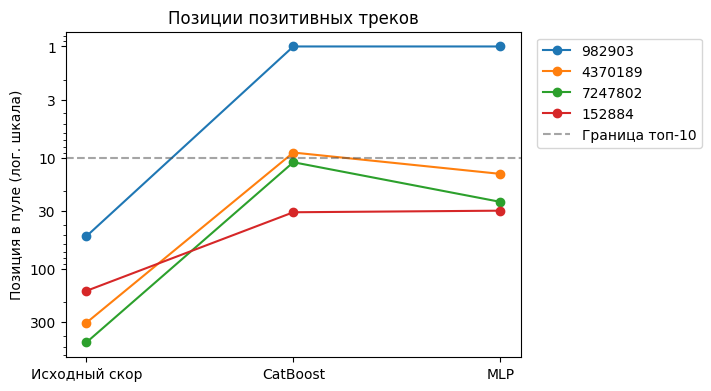

In [ ]:
user_row = int(np.random.default_rng(SEED).integers(len(test.users)))
demo_user_id = int(test.users[user_row])

def top10(scores):
    real = np.flatnonzero(test.cands[user_row] > 0)
    top = real[np.argsort(-scores[user_row, real], kind='stable')[:10]]
    return pd.DataFrame({
        'трек': test.cands[user_row, top],
        'позитив': test.listen[user_row, top],
    }, index=np.arange(1, len(top) + 1))

print('Пользователь:', test.users[user_row])
display(pd.concat({
    'По скору генератора': top10(retrieval_scores),
    'После CatBoost': top10(catboost_scores),
    'После MLP': top10(mlp_scores),
}, axis=1))

def candidate_ranks(scores):
    order = np.argsort(-scores[user_row], kind='stable')
    return order.argsort() + 1

before = candidate_ranks(retrieval_scores)
tree = candidate_ranks(catboost_scores)
after = candidate_ranks(mlp_scores)
hits = np.flatnonzero(test.listen[user_row] > 0)
# Берём до восьми позитивов, поднявшихся ближе всего к началу хотя бы в одной выдаче.
closest = np.minimum(np.minimum(before, tree), after)
shown = hits[np.argsort(closest[hits], kind='stable')[:8]]
fig, ax = plt.subplots(figsize=(7, 3.8), layout='constrained')
for col in shown:
    ax.plot(['Исходный скор', 'CatBoost', 'MLP'], [before[col], tree[col], after[col]],
            marker='o', label=str(test.cands[user_row, col]))
ax.axhline(10, ls='--', color='#4d4d4d', alpha=0.5, label='Граница топ-10')
ax.set(yscale='log', ylabel='Позиция в пуле (лог. шкала)', title='Позиции позитивных треков')
max_position = max(10, np.concatenate([before[shown], tree[shown], after[shown]]).max(initial=0))
ticks = [rank for rank in (1, 3, 10, 30, 100, 300, 500) if rank <= max_position]
ax.set_yticks(ticks, labels=[str(rank) for rank in ticks])
ax.invert_yaxis()
if len(shown):
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

### 1.7. Итоговые рекомендации

Для нового запроса используем только события до временной отсечки. Пересчитываем кандидатов и признаки, применяем MLP и возвращаем топ-10.

In [ ]:
def recommend(user_id, at, top_k=10):
    if split.cutoff(at) < val.T + split.day:
        raise ValueError('Выберите момент после окончания валидационного дня и 30-минутного зазора')
    past_listens = events_before(listens, at, split)
    past_likes = events_before(likes, at, split)
    past_positives = positive_listens(past_listens)
    candidates = build_slice(
        at, past_positives, past_listens, past_likes, source, split,
        users=[user_id], k=K, n_popular=N_POPULAR, artist_index=artists,
    )
    pair_features = history_features(
        candidates, past_positives, source, split, max_history=HISTORY_LENGTH,
    )
    candidates = replace(candidates, X_num=pd.concat(
        [candidates.X_num, pair_features], axis=1, copy=False,
    ))
    scores = predict_torch(ranker, encoder, candidates, normalizer)[0]
    valid = np.flatnonzero(candidates.cands[0] > 0)
    top = valid[np.argsort(-scores[valid], kind='stable')[:top_k]]
    return pd.DataFrame({
        'место': np.arange(1, len(top) + 1),
        'трек': candidates.cands[0, top],
        'скор': scores[top],
    })

print('Пользователь:', demo_user_id)
final_top10 = recommend(demo_user_id, at=test.T)
final_top10.to_csv(root / 'top10.csv', index=False)
display(final_top10)

Пользователь: 85100


,место,трек,скор
0,1,982903,12.934538
1,2,9100965,12.504893
2,3,3811863,12.434284
3,4,2850842,12.367223
4,5,5672520,12.360209
5,6,3596664,12.156796
6,7,6826570,12.110630
7,8,4787965,12.101887
8,9,8632822,12.052347
9,10,6563722,12.050460


**Вывод.** Ранжирование существенно улучшает топ-10 относительно исходного SASRec. На тесте MLP немного лучше CatBoost, но доверительный интервал разности перекрывает ноль. Основное ограничение остаётся на этапе отбора: **67.8%** таргетов вне пула.

## 2. Размер обучения и DCN-V2

### 2.1. Объём обучения

Сравниваем MLP и CatBoost на вложенных выборках групп с позитивом. Валидируем на одном и том же дне.

In [ ]:
import gc
import time

def take_groups(day, indices):
    width = day.cands.shape[1]
    rows = (indices[:, None] * width + np.arange(width)).ravel()
    return replace(
        day,
        users=day.users[indices], cands=day.cands[indices],
        listen=day.listen[indices], like=day.like[indices],
        n_listen=day.n_listen[indices], n_like=day.n_like[indices],
        item_idx=day.item_idx[rows], artist_idx=day.artist_idx[rows],
        group=np.repeat(np.arange(len(indices)), width),
        X_num=day.X_num.iloc[rows].reset_index(drop=True),
    )

def scale_inputs(train_days, norm, path):
    width = train_days[0].cands.shape[1]
    count = sum(len(day.users) for day in train_days)
    numbers = np.memmap(path, mode='w+', dtype=np.float32, shape=(count, width, norm.n_out))
    offset = 0
    for day in train_days:
        for start in range(0, len(day.users), 128):
            end = min(start + 128, len(day.users))
            frame = day.X_num.iloc[start * width:end * width]
            numbers[offset + start:offset + end] = norm.transform(frame).reshape(-1, width, norm.n_out)
        offset += len(day.users)
    return tuple(map(torch.from_numpy, (
        numbers,
        np.concatenate([day.artist_idx.reshape(day.cands.shape) for day in train_days]),
        np.concatenate([day.listen for day in train_days]),
        np.concatenate([day.cands > 0 for day in train_days]),
    )))

def val_user_ndcg(scores, labels):
    top = _top_k_labels(scores, labels, 10)
    discounts = 1. / np.log2(np.arange(2, top.shape[1] + 2))
    ideal = np.r_[1., discounts.cumsum()][np.minimum(labels.sum(axis=1), len(discounts))]
    return (top @ discounts) / ideal

def run_learning_curve(train_days, validation, destination, *, seed=42, fractions=(0.25, 0.5, 1.),
                       mlp_epochs=12, catboost_iterations=1000, training_device='cuda', n_artists=None):
    destination.mkdir(exist_ok=True, parents=True)
    rng = np.random.default_rng(seed)
    orders = [rng.permutation(np.flatnonzero(day.listen.any(axis=1))) for day in train_days]
    if any(not len(indices) for indices in orders):
        raise ValueError('Нужна хотя бы одна обучающая группа с позитивом на каждом срезе')
    if n_artists is None:
        n_artists = max(int(day.artist_idx.max()) for day in [*train_days, validation])
    (destination / 'config.json').write_text(json.dumps({
        'seed': seed, 'fractions': fractions, 'val_time': int(validation.T),
        'val_users': len(validation.users), 'candidate_width': validation.cands.shape[1],
        'mlp_epochs': mlp_epochs, 'catboost_iterations': catboost_iterations,
        'mlp_negatives': 56, 'catboost_negatives': 100, 'n_artists': n_artists,
    }, indent=2))
    rows = []
    for fraction in fractions:
        started = time.monotonic()
        indices = [np.sort(order[:max(1, int(len(order) * fraction))]) for order in orders]
        current = [take_groups(day, keep) for day, keep in zip(train_days, indices)]
        count = sum(map(len, indices))
        print(f'Доля {fraction:.0%}: {count:,} общих обучающих групп', flush=True)
        np.savez_compressed(destination / f'train-ids-{fraction:g}.npz', **{
            f'day_{i}': day.users for i, day in enumerate(current)
        })
        samples = pd.concat([
            day.X_num.sample(n=min(len(day.X_num), 150_000), random_state=seed)
            for day in current
        ], ignore_index=True)
        numeric = NumericNormalizer().fit(samples[NUM_FEATURES])
        norm = HistoryNormalizer(numeric, samples.iloc[:, len(NUM_FEATURES):])
        del samples
        with TemporaryDirectory(dir=destination) as tmp:
            inputs = scale_inputs(current, norm, Path(tmp) / 'numeric.bin')
            mlp, artist_encoder, history = fit_grouped(
                current, validation, norm, lambda width: PiecewiseRanker(width, norm.n_out),
                kind='listwise', seed=seed, device=training_device, epochs=mlp_epochs,
                negatives=56, batch_groups=80, d_artist=8, n_artists=n_artists, inputs=inputs,
            )
            del inputs
        mlp_scores = predict_torch(mlp, artist_encoder, validation, norm)
        del mlp, artist_encoder
        gc.collect()
        if training_device == 'cuda':
            torch.cuda.empty_cache()
        tree = fit_catboost(
            current, validation, iterations=catboost_iterations, neg_per_group=100,
            task_type='GPU' if training_device == 'cuda' else 'CPU', verbose=50,
        )
        tree_scores = predict_catboost(tree, validation)
        mlp_ndcg = val_user_ndcg(mlp_scores, validation.listen)
        tree_ndcg = val_user_ndcg(tree_scores, validation.listen)
        delta = mlp_ndcg - tree_ndcg
        bootstrap_rng = np.random.default_rng(seed)
        bootstrap = [delta[bootstrap_rng.integers(len(delta), size=len(delta))].mean()
                     for _ in range(2_000)]
        low, high = np.quantile(bootstrap, [0.025, 0.975])
        row = dict(seed=seed, train_fraction=fraction, train_groups=count,
                   mlp_ndcg10=mlp_ndcg.mean(), catboost_ndcg10=tree_ndcg.mean(),
                   mlp_recall10=recall_at_k(mlp_scores, validation.listen, validation.n_listen),
                   catboost_recall10=recall_at_k(tree_scores, validation.listen, validation.n_listen),
                   delta_ndcg10=delta.mean(), ci_low=low, ci_high=high,
                   mlp_epoch=1 + int(np.argmax(history)), catboost_trees=tree.tree_count_,
                   seconds=round(time.monotonic() - started, 1))
        rows.append(row)
        np.savez_compressed(destination / f'val-ndcg-{fraction:g}.npz',
                            users=validation.users, mlp=mlp_ndcg, catboost=tree_ndcg)
        temp_csv = destination / 'results.tmp.csv'
        pd.DataFrame(rows).to_csv(temp_csv, index=False)
        temp_csv.replace(destination / 'results.csv')
        print(row, flush=True)
        del current, tree, mlp_scores, tree_scores
        gc.collect()
    return pd.DataFrame(rows)

Доля 25%: 3,437 общих обучающих групп
listwise, seed=42, epoch=1: val NDCG@10=0.330520
listwise, seed=42, epoch=2: val NDCG@10=0.331526
listwise, seed=42, epoch=3: val NDCG@10=0.337577
listwise, seed=42, epoch=4: val NDCG@10=0.338374
listwise, seed=42, epoch=5: val NDCG@10=0.338312
listwise, seed=42, epoch=6: val NDCG@10=0.341814
listwise, seed=42, epoch=7: val NDCG@10=0.340593
listwise, seed=42, epoch=8: val NDCG@10=0.342577
listwise, seed=42, epoch=9: val NDCG@10=0.345109
listwise, seed=42, epoch=10: val NDCG@10=0.343123
listwise, seed=42, epoch=11: val NDCG@10=0.345802
listwise, seed=42, epoch=12: val NDCG@10=0.342930
Groupwise loss function. OneHotMaxSize set to 10


Default metric period is 5 because NDCG is/are not implemented for GPU
Metric NDCG:top=10;type=Base is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time


0:	test: 0.2792171	best: 0.2792171 (0)	total: 246ms	remaining: 4m 5s
50:	test: 0.4336123	best: 0.4336123 (50)	total: 4.38s	remaining: 1m 21s
100:	test: 0.4441629	best: 0.4441629 (100)	total: 9.39s	remaining: 1m 23s
150:	test: 0.4491941	best: 0.4491941 (150)	total: 13.4s	remaining: 1m 15s
200:	test: 0.4542667	best: 0.4545147 (198)	total: 17.5s	remaining: 1m 9s
250:	test: 0.4566221	best: 0.4566914 (244)	total: 22.5s	remaining: 1m 7s
300:	test: 0.4577864	best: 0.4581722 (288)	total: 26.6s	remaining: 1m 1s
350:	test: 0.4586956	best: 0.4587388 (349)	total: 30.5s	remaining: 56.5s
400:	test: 0.4594044	best: 0.4602595 (387)	total: 35.4s	remaining: 52.9s
bestTest = 0.4602594759
bestIteration = 387
Shrink model to first 388 iterations.
{'seed': 42, 'train_fraction': 0.25, 'train_groups': 3437, 'mlp_ndcg10': np.float64(0.3458019246460169), 'catboost_ndcg10': np.float64(0.3430611420782957), 'mlp_recall10': 0.16333516840693693, 'catboost_recall10': 0.16361943788132835, 'delta_ndcg10': np.float64(0.

Default metric period is 5 because NDCG is/are not implemented for GPU
Metric NDCG:top=10;type=Base is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time


0:	test: 0.3208593	best: 0.3208593 (0)	total: 309ms	remaining: 5m 8s
50:	test: 0.4315584	best: 0.4315584 (50)	total: 7.17s	remaining: 2m 13s
100:	test: 0.4489724	best: 0.4491879 (99)	total: 13.3s	remaining: 1m 58s
150:	test: 0.4539628	best: 0.4539815 (147)	total: 20.2s	remaining: 1m 53s
200:	test: 0.4560231	best: 0.4562318 (187)	total: 26.3s	remaining: 1m 44s
250:	test: 0.4589544	best: 0.4590093 (249)	total: 33.1s	remaining: 1m 38s
300:	test: 0.4610769	best: 0.4612219 (298)	total: 39.1s	remaining: 1m 30s
350:	test: 0.4610624	best: 0.4616877 (338)	total: 45.8s	remaining: 1m 24s
400:	test: 0.4625823	best: 0.4627579 (394)	total: 51.8s	remaining: 1m 17s
450:	test: 0.4634585	best: 0.4636025 (444)	total: 58.5s	remaining: 1m 11s
500:	test: 0.4635788	best: 0.4637372 (486)	total: 1m 4s	remaining: 1m 4s
550:	test: 0.4628701	best: 0.4638412 (503)	total: 1m 11s	remaining: 57.9s
bestTest = 0.463841237
bestIteration = 503
Shrink model to first 504 iterations.
{'seed': 42, 'train_fraction': 0.5, 'tra

Default metric period is 5 because NDCG is/are not implemented for GPU
Metric NDCG:top=10;type=Base is not implemented on GPU. Will use CPU for metric computation, this could significantly affect learning time


0:	test: 0.2660383	best: 0.2660383 (0)	total: 414ms	remaining: 6m 53s
50:	test: 0.4290861	best: 0.4290861 (50)	total: 11.6s	remaining: 3m 35s
100:	test: 0.4485854	best: 0.4486660 (99)	total: 22.8s	remaining: 3m 22s
150:	test: 0.4555268	best: 0.4555268 (150)	total: 33.9s	remaining: 3m 10s
200:	test: 0.4586240	best: 0.4586240 (200)	total: 44.8s	remaining: 2m 58s
250:	test: 0.4599736	best: 0.4601550 (240)	total: 55.7s	remaining: 2m 46s
300:	test: 0.4629996	best: 0.4629996 (300)	total: 1m 6s	remaining: 2m 33s
350:	test: 0.4652970	best: 0.4656060 (348)	total: 1m 16s	remaining: 2m 22s
400:	test: 0.4659252	best: 0.4659753 (386)	total: 1m 27s	remaining: 2m 10s
450:	test: 0.4666322	best: 0.4666322 (450)	total: 1m 38s	remaining: 1m 59s
500:	test: 0.4664095	best: 0.4675087 (483)	total: 1m 49s	remaining: 1m 48s
bestTest = 0.4675086843
bestIteration = 483
Shrink model to first 484 iterations.
{'seed': 42, 'train_fraction': 1.0, 'train_groups': 13756, 'mlp_ndcg10': np.float64(0.34872957566037843), '

,train_groups,mlp_ndcg10,catboost_ndcg10,delta_ndcg10,ci_low,ci_high
0,3437,0.34580,0.34306,0.00274,-0.00164,0.00688
1,6877,0.34983,0.34573,0.00410,0.00005,0.00799
2,13756,0.34873,0.34846,0.00027,-0.00357,0.00391


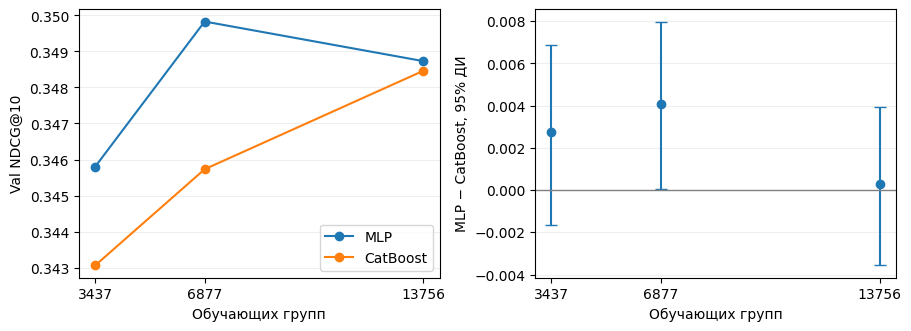

In [ ]:
scale = run_learning_curve(train, val, root / 'learning-curve', seed=SEED,
                           mlp_epochs=RANKER_EPOCHS, catboost_iterations=CATBOOST_ITERATIONS,
                           training_device=device, n_artists=int(artists.max()))
display(scale[['train_groups', 'mlp_ndcg10', 'catboost_ndcg10', 'delta_ndcg10',
               'ci_low', 'ci_high']].round(5))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), layout='constrained')
x = scale.train_groups
axes[0].plot(x, scale.mlp_ndcg10, marker='o', label='MLP')
axes[0].plot(x, scale.catboost_ndcg10, marker='o', label='CatBoost')
axes[0].set(ylabel='Val NDCG@10')
axes[0].legend()
axes[1].errorbar(x, scale.delta_ndcg10,
                 yerr=[scale.delta_ndcg10-scale.ci_low, scale.ci_high-scale.delta_ndcg10],
                 fmt='o', capsize=4)
axes[1].axhline(0, color='#808080', lw=1)
axes[1].set(ylabel='MLP − CatBoost, 95% ДИ')
for ax in axes:
    ax.set(xlabel='Обучающих групп', xticks=x)
    ax.grid(axis='y', alpha=.2)
plt.show()

**По объёму обучения.** Val NDCG@10 (MLP / CatBoost): 25% — **0.3458 / 0.3431**, 50% — **0.3498 / 0.3457**, 100% — **0.3487 / 0.3485**. Монотонного роста на этом срезе нет.

### 2.2. DCN-V2

Добавляем четыре cross-слоя: $x_{l+1}=x_l+x_0\odot(U_l V_l^\top x_l+b_l)$. Сравниваем глубины 0 и 4 для двух seed.

In [ ]:
class CrossLayerV2(nn.Module):
    """x_{l+1} = x0 * (U (V^T x_l) + b) + x_l; низкоранговая матрица W = U V."""

    def __init__(self, d, rank):
        super().__init__()
        self.V = nn.Linear(d, rank, bias=False)
        self.U = nn.Linear(rank, d, bias=False)
        self.b = nn.Parameter(torch.zeros(d))

    def forward(self, x0, xl):
        return x0 * (self.U(self.V(xl)) + self.b) + xl

class CrossAblationRanker(PiecewiseRanker):
    def __init__(self, d_in, n_numeric, n_cross, cross_rank=16):
        super().__init__(d_in, n_numeric)
        # Preserve the random stream for the shared layers and dropout.
        with torch.random.fork_rng(devices=[]):
            width = n_numeric * 13 + d_in - n_numeric
            self.cross = nn.ModuleList([CrossLayerV2(width, cross_rank) for _ in range(n_cross)])
            for layer in self.cross:
                nn.init.zeros_(layer.U.weight)

    def forward(self, x):
        n_categorical = x.shape[1] - self.n_numeric
        z = x[:, n_categorical:]
        basis = torch.cat([z, F.relu(z[..., None] - self.knots).flatten(1)], dim=1)
        x0 = torch.cat([basis, x[:, :n_categorical]], dim=1)
        crossed = x0
        for layer in self.cross:
            crossed = layer(x0, crossed)
        return self.additive(basis) + self.mlp(crossed)


def check_matched_initialization(d_in, n_numeric, seed):
    with torch.random.fork_rng(devices=[]):
        x = torch.linspace(-1, 1, 3 * d_in).reshape(3, d_in)
        torch.manual_seed(seed)
        baseline = PiecewiseRanker(d_in, n_numeric)
        original_rng = torch.get_rng_state()
        for depth in (0, 4):
            torch.manual_seed(seed)
            model = CrossAblationRanker(d_in, n_numeric, depth)
            assert torch.equal(torch.get_rng_state(), original_rng)
            assert all(torch.equal(model.state_dict()[name], value)
                       for name, value in baseline.state_dict().items())
            torch.testing.assert_close(model.eval()(x), baseline.eval()(x), rtol=0, atol=0)
        model.train()(x).sum().backward()
        assert all(layer.U.weight.grad.abs().sum() > 0 for layer in model.cross)


def paired_interval(delta, seed=42):
    rng = np.random.default_rng(seed)
    means = np.concatenate([
        delta[rng.integers(len(delta), size=(50, len(delta)))].mean(axis=1)
        for _ in range(40)
    ])
    return [float(delta.mean()), *map(float, np.quantile(means, [0.025, 0.975]))]

In [ ]:
seeds = (42, 73)
checkpoints = {}
cross_rows = []
fit_settings = dict(kind='listwise', device=device, epochs=RANKER_EPOCHS,
                    negatives=56, batch_groups=80, d_artist=8, n_artists=int(artists.max()))

def fit_ranking_variant(factory, seed, fit_days=train, validation=val, norm=normalizer):
    return fit_mlp(fit_days, validation, norm, factory, seed=seed, **fit_settings)

for seed in seeds:
    check_matched_initialization(normalizer.n_out + 8, normalizer.n_out, seed)
    for depth in (0, 4):
        print(f'Cross: seed {seed}, глубина {depth}', flush=True)
        if seed == SEED and depth == 0:
            model, artist_encoder, history = ranker, encoder, curve
        else:
            model, artist_encoder, history = fit_ranking_variant(
                lambda width: CrossAblationRanker(width, normalizer.n_out, depth), seed,
            )
        checkpoints[seed, depth] = (model, artist_encoder)
        cross_rows.append({'seed': seed, 'depth': depth, 'val_ndcg10': max(history),
                           'best_epoch': 1 + int(np.argmax(history))})
cross_validation = pd.DataFrame(cross_rows)
best_depth = int(cross_validation.groupby('depth').val_ndcg10.mean().idxmax())
display(cross_validation.round(6))
print(f'Глубина по валидации: {best_depth}')

Cross: seed 42, глубина 0
Cross: seed 42, глубина 4
Обучающих групп с позитивом в пуле: 13,756
listwise, seed=42, epoch=1: val NDCG@10=0.343608
listwise, seed=42, epoch=2: val NDCG@10=0.350313
listwise, seed=42, epoch=3: val NDCG@10=0.354554
listwise, seed=42, epoch=4: val NDCG@10=0.352473
listwise, seed=42, epoch=5: val NDCG@10=0.357448
listwise, seed=42, epoch=6: val NDCG@10=0.355746
listwise, seed=42, epoch=7: val NDCG@10=0.354279
Cross: seed 73, глубина 0
Обучающих групп с позитивом в пуле: 13,756
listwise, seed=73, epoch=1: val NDCG@10=0.340551
listwise, seed=73, epoch=2: val NDCG@10=0.344633
listwise, seed=73, epoch=3: val NDCG@10=0.347602
listwise, seed=73, epoch=4: val NDCG@10=0.347201
listwise, seed=73, epoch=5: val NDCG@10=0.349495
listwise, seed=73, epoch=6: val NDCG@10=0.347660
listwise, seed=73, epoch=7: val NDCG@10=0.350229
listwise, seed=73, epoch=8: val NDCG@10=0.348114
listwise, seed=73, epoch=9: val NDCG@10=0.349971
Cross: seed 73, глубина 4
Обучающих групп с позитиво

,seed,depth,val_ndcg10,best_epoch
0,42,0,0.351968,12
1,42,4,0.357448,5
2,73,0,0.350229,7
3,73,4,0.357449,7


Глубина по валидации: 4


**По DCN.** При seed 42/73 Val NDCG@10 без cross-слоёв — **0.35197 / 0.35023**, с четырьмя слоями — **0.35745 / 0.35745**. По val выбрана глубина **4**.

## 3. Time2Vec в DCN

Для давности $t=\log(1+\Delta t_{\text{дни}})$ используем четыре координаты: линейную и три синусные. Для неизвестной давности весь вектор обнуляется маской. Кодировку включаем в $x_0$ до cross-слоёв:

$$e(t)=[\omega_0t+b_0,\ \sin(\omega_1t+b_1),\ \sin(\omega_2t+b_2),\ \sin(\omega_3t+b_3)].$$

In [ ]:
class CrossTimeInputRanker(CrossAblationRanker):
    def __init__(self, d_in, n_numeric):
        super().__init__(d_in - 2, n_numeric, n_cross=4)
        self.frequency = nn.Parameter(torch.tensor([0.1, 1., 2., 4.]))
        self.phase = nn.Parameter(torch.tensor([0., 0., np.pi / 2, 0.]))
        n_time = self.frequency.numel()
        width = self.mlp[0].in_features
        # Start from the same shared weights and preserve the dropout RNG stream.
        with torch.random.fork_rng(devices=[]), torch.no_grad():
            for i, old in enumerate(self.cross):
                layer = CrossLayerV2(width + n_time, old.V.out_features)
                layer.V.weight[:, :width].copy_(old.V.weight)
                layer.U.weight.zero_()
                layer.U.weight[:width].copy_(old.U.weight)
                layer.b[:width].copy_(old.b)
                self.cross[i] = layer
            old = self.mlp[0]
            projection = nn.Linear(width + n_time, old.out_features)
            projection.weight.zero_()
            projection.weight[:, :width].copy_(old.weight)
            projection.bias.copy_(old.bias)
            self.mlp[0] = projection

    def forward(self, x):
        features, t, known = x[:, :-2], x[:, -2:-1], x[:, -1:]
        z = features[:, -self.n_numeric:]
        categorical = features[:, :-self.n_numeric]
        basis = torch.cat([z, F.relu(z[..., None] - self.knots).flatten(1)], dim=1)
        phase = t * self.frequency + self.phase
        temporal = torch.cat([phase[:, :1], phase[:, 1:].sin()], dim=1) * known

        x0 = torch.cat([basis, categorical, temporal], dim=1)
        crossed = x0
        for layer in self.cross:
            crossed = layer(x0, crossed)
        return self.additive(basis) + self.mlp(crossed)



def time_values(hours, cutoff_days, *, recency):
    hours = np.asarray(hours, dtype=np.float32)
    known = np.isfinite(hours)
    days = np.where(known, hours / 24, 0)
    value = np.log1p(days) if recency else cutoff_days - days
    return np.where(known, value, 0).astype(np.float32), known.astype(np.float32)


def time_day(day):
    frame = day.X_num.copy(deep=False)
    frame['__cutoff'] = np.float32(split.cutoff(day.T))
    return replace(day, X_num=frame)

class MatchedTimeNorm:
    n_out = normalizer.n_out + 2

    def __init__(self, recency):
        self.recency = recency

    def transform(self, frame):
        cutoff = (int(frame['__cutoff'].iloc[0]) - split.window_start) / split.day
        values, known = time_values(frame['ui_last_dt_hours'], cutoff, recency=self.recency)
        return np.column_stack([normalizer.transform(frame.iloc[:, :-1]), values, known])

In [ ]:
# Пример на трёх кандидатах. Двух числовых признаков достаточно для демонстрации.
hours = np.array([24., 168., np.nan], dtype=np.float32)
t, known = time_values(hours, cutoff_days=0, recency=True)
with torch.random.fork_rng(devices=[]):
    example_dcn = CrossTimeInputRanker(4, n_numeric=2)
with torch.no_grad():
    phase = torch.from_numpy(t[:, None]) * example_dcn.frequency + example_dcn.phase
    temporal = torch.cat([phase[:, :1], phase[:, 1:].sin()], dim=1)
    temporal = temporal * torch.from_numpy(known[:, None])
    x0_width = example_dcn.cross[0].V.in_features

display(pd.DataFrame({
    'давность, ч': hours,
    't = log1p(дни)': t,
    'маска': known.astype(int),
    'линейная координата': temporal[:, 0].numpy(),
    'синус 1': temporal[:, 1].numpy(),
    'синус 2': temporal[:, 2].numpy(),
    'синус 3': temporal[:, 3].numpy(),
}).round(4))
print(f'Размер x₀ в этом примере: {x0_width - temporal.shape[1]} + '
      f'{temporal.shape[1]} = {x0_width}. '
      'Последние четыре координаты получает каждый cross-слой.')

,"давность, ч",t = log1p(дни),маска,линейная координата,синус 1,синус 2,синус 3
0,24.0,0.6931,1,0.0693,0.6390,0.1835,0.3607
1,168.0,2.0794,1,0.2079,0.8734,-0.5257,0.8944
2,NaN,0.0000,0,0.0000,0.0000,0.0000,0.0000


Размер x₀ в этом примере: 26 + 4 = 30. Последние четыре координаты получает каждый cross-слой.


In [ ]:
# @title Обучение DCN с Time2Vec на входе x₀
timed_train = [time_day(day) for day in train]
timed_val, timed_test = time_day(val), time_day(test)
timed_norm = MatchedTimeNorm(recency=True)

time_cross, time_cross_val = {}, {}
time_rows = []
for x0_seed in seeds:
    print(f'Time2Vec в x₀, seed {x0_seed}', flush=True)
    with torch.random.fork_rng(devices=[]):
        x = torch.randn(6, normalizer.n_out + 8)
        t = torch.linspace(0., 3., len(x))[:, None]
        torch.manual_seed(x0_seed)
        x0_control = CrossAblationRanker(x.shape[1], normalizer.n_out, 4).eval()
        torch.manual_seed(x0_seed)
        x0_variant = CrossTimeInputRanker(x.shape[1] + 2, normalizer.n_out).eval()
        torch.testing.assert_close(x0_variant(torch.cat([x, t, torch.ones_like(t)], dim=1)),
                                   x0_control(x), atol=1e-6, rtol=1e-6)

    x0_model, x0_encoder, x0_history = fit_ranking_variant(
        lambda width: CrossTimeInputRanker(width, normalizer.n_out),
        x0_seed, timed_train, timed_val, timed_norm,
    )
    time_cross[x0_seed] = (x0_model, x0_encoder)
    time_cross_val[x0_seed] = max(x0_history)
    baseline_val = cross_validation.loc[
        (cross_validation.seed == x0_seed) & (cross_validation.depth == 4), 'val_ndcg10'
    ].item()
    time_rows.append({
        'seed': x0_seed,
        'DCN Val NDCG@10': baseline_val,
        'DCN + Time2Vec в x₀ Val NDCG@10': max(x0_history),
        'Δ Val NDCG@10': max(x0_history) - baseline_val,
        'лучшая эпоха': 1 + int(np.argmax(x0_history)),
    })

display(pd.DataFrame(time_rows).round(6))

Time2Vec в x₀, seed 42
Обучающих групп с позитивом в пуле: 13,756
listwise, seed=42, epoch=1: val NDCG@10=0.343860
listwise, seed=42, epoch=2: val NDCG@10=0.349948
listwise, seed=42, epoch=3: val NDCG@10=0.354958
listwise, seed=42, epoch=4: val NDCG@10=0.353032
listwise, seed=42, epoch=5: val NDCG@10=0.355710
listwise, seed=42, epoch=6: val NDCG@10=0.356102
listwise, seed=42, epoch=7: val NDCG@10=0.355288
listwise, seed=42, epoch=8: val NDCG@10=0.351731
Time2Vec в x₀, seed 73
Обучающих групп с позитивом в пуле: 13,756
listwise, seed=73, epoch=1: val NDCG@10=0.344526
listwise, seed=73, epoch=2: val NDCG@10=0.354776
listwise, seed=73, epoch=3: val NDCG@10=0.355538
listwise, seed=73, epoch=4: val NDCG@10=0.355128
listwise, seed=73, epoch=5: val NDCG@10=0.357102
listwise, seed=73, epoch=6: val NDCG@10=0.355584
listwise, seed=73, epoch=7: val NDCG@10=0.357072


,seed,DCN Val NDCG@10,DCN + Time2Vec в x₀ Val NDCG@10,Δ Val NDCG@10,лучшая эпоха
0,42,0.357448,0.356102,-0.001346,6
1,73,0.357449,0.357102,-0.000347,5


**По Time2Vec.** Val NDCG@10 снизился на **0.00135** и **0.00035** (seed 42/73). На тесте Time2Vec дал небольшой прирост, но оба 95% ДИ разности включают ноль. Устойчивый выигрыш не подтверждён.

## 4. FCN и итог

FCN: ветки LCN и ECN, общий listwise-лосс. Сравниваем с MLP, CatBoost и DCN на том же тестовом пуле.

In [ ]:
class FCNCrossLayer(nn.Module):
    def __init__(self, n_numeric, n_categorical):
        super().__init__()
        self.n_numeric = n_numeric
        self.numeric_half = n_numeric * 7
        width = n_numeric * 14 + n_categorical
        self.project_half = nn.Linear(width, width // 2)
        self.scale = nn.Parameter(torch.ones(width // 2))
        self.shift = nn.Parameter(torch.zeros(width // 2))
        with torch.no_grad():
            self.project_half.weight.mul_(0.25)
            self.project_half.bias.zero_()

    def forward(self, anchor, current):
        half = self.project_half(current)
        affine = half * self.scale + self.shift
        a = half[:, :self.numeric_half].unflatten(1, (self.n_numeric, 7))
        b = affine[:, :self.numeric_half].unflatten(1, (self.n_numeric, 7))
        numeric = torch.cat((a, b), dim=-1).flatten(1)
        aggregated = torch.cat((numeric, half[:, self.numeric_half:], affine[:, self.numeric_half:]), dim=1)
        return current + anchor * aggregated


class FCNListwiseRanker(nn.Module):
    def __init__(self, d_in, n_numeric, depth=4):
        super().__init__()
        self.n_numeric = n_numeric
        self.n_categorical = d_in - n_numeric
        assert self.n_categorical % 2 == 0
        self.register_buffer('knots', torch.linspace(-0.85, 0.85, 12))
        self.lcn = nn.ModuleList(FCNCrossLayer(n_numeric, self.n_categorical) for _ in range(depth))
        self.ecn = nn.ModuleList(FCNCrossLayer(n_numeric, self.n_categorical) for _ in range(depth))
        width = 14 * n_numeric + self.n_categorical
        self.lcn_head = nn.Linear(width, 1)
        self.ecn_head = nn.Linear(width, 1)

    def branch_logits(self, x):
        z = x[:, self.n_categorical:, None]
        # Repeat the raw coordinate in each numeric basis so LCA can split it evenly.
        numeric = torch.cat((z, F.relu(z - self.knots), z), dim=-1).flatten(1)
        x0 = torch.cat((numeric, x[:, :self.n_categorical]), dim=1)
        linear = exponential = x0
        for lcn, ecn in zip(self.lcn, self.ecn):
            linear = lcn(x0, linear)
            exponential = ecn(exponential, exponential)
        return self.lcn_head(linear), self.ecn_head(exponential)

    def forward(self, x):
        linear, exponential = self.branch_logits(x)
        # The logit of the mean of branch probabilities is the score for the shared listwise loss.
        return (torch.logaddexp(F.logsigmoid(linear), F.logsigmoid(exponential))
                - torch.logaddexp(F.logsigmoid(-linear), F.logsigmoid(-exponential)))

In [ ]:
fcn = {}
fcn_val = {}
for seed in seeds:
    model, artist_encoder, history = fit_ranking_variant(
        lambda width: FCNListwiseRanker(width, normalizer.n_out), seed,
    )
    fcn[seed] = (model, artist_encoder)
    fcn_val[seed] = max(history)

Обучающих групп с позитивом в пуле: 13,756
listwise, seed=42, epoch=1: val NDCG@10=0.346439
listwise, seed=42, epoch=2: val NDCG@10=0.350587
listwise, seed=42, epoch=3: val NDCG@10=0.352490
listwise, seed=42, epoch=4: val NDCG@10=0.347853
listwise, seed=42, epoch=5: val NDCG@10=0.349575
Обучающих групп с позитивом в пуле: 13,756
listwise, seed=73, epoch=1: val NDCG@10=0.350876
listwise, seed=73, epoch=2: val NDCG@10=0.351166
listwise, seed=73, epoch=3: val NDCG@10=0.352985
listwise, seed=73, epoch=4: val NDCG@10=0.352510
listwise, seed=73, epoch=5: val NDCG@10=0.353175
listwise, seed=73, epoch=6: val NDCG@10=0.352553
listwise, seed=73, epoch=7: val NDCG@10=0.343949


In [ ]:
def is_repeat(d):
    # повтор — кандидат, которого пользователь дослушивал до отсечки среза; [U, k]
    return (d.X_num['ui_cnt'].to_numpy() > 0).reshape(d.cands.shape)


def segment_ndcg(scores, d):
    """NDCG@10 listen по сегментам «все / повторы / новые»: ранжирование по всем кандидатам,
    позитивы — только из сегмента, среднее по пользователям с позитивом в сегменте."""
    rep = is_repeat(d)
    out = {}
    for seg, mask in (('все', np.ones_like(rep)), ('повторы', rep), ('новые', ~rep)):
        lab = d.listen * mask
        ok = lab.sum(1) > 0
        out[seg] = ndcg_at_k(scores[ok], lab[ok]) if ok.any() else float('nan')
        out[f'пользователей ({seg})'] = int(ok.sum())
    return out


rows, comparisons, segments = [], [], []
catboost_val = ndcg_at_k(predict_catboost(catboost, val), val.listen)
for seed in seeds:
    val_by_depth = cross_validation.query('seed == @seed').set_index('depth').val_ndcg10
    scoring = {
        'CatBoost': (catboost_scores, catboost_val),
        'MLP': (predict_torch(*checkpoints[seed, 0], test, normalizer), val_by_depth[0]),
        'DCN, 4 слоя': (predict_torch(*checkpoints[seed, 4], test, normalizer), val_by_depth[4]),
        'DCN + Time2Vec в x₀': (predict_torch(*time_cross[seed], timed_test, timed_norm), time_cross_val[seed]),
        'FCN': (predict_torch(*fcn[seed], test, normalizer), fcn_val[seed]),
    }
    for name, (scores, val_score) in scoring.items():
        selected_depth = (name == ('DCN, 4 слоя' if best_depth == 4 else 'MLP'))
        rows.append({'seed': seed, 'модель': name, 'глубина выбрана по val': 'да' if selected_depth else '',
                     'Val NDCG@10': val_score, **evaluate(scores)})
        if name in ('DCN, 4 слоя', 'DCN + Time2Vec в x₀'):
            segments.append({'seed': seed, 'модель': name, **segment_ndcg(scores, test)})
    for name, reference in [('DCN, 4 слоя', 'MLP'), ('DCN, 4 слоя', 'CatBoost'),
                            ('DCN + Time2Vec в x₀', 'DCN, 4 слоя'),
                            ('FCN', 'DCN, 4 слоя')]:
        delta, low, high = paired_interval(user_ndcg(scoring[name][0]) - user_ndcg(scoring[reference][0]))
        comparisons.append({'seed': seed, 'разница': f'{name} − {reference}',
                            'Δ NDCG@10': delta, '95% ДИ, низ': low, '95% ДИ, верх': high})
results_by_seed = pd.DataFrame(rows)
intervals_by_seed = pd.DataFrame(comparisons)
display(results_by_seed.round(6))
display(intervals_by_seed.round(6))
display(pd.DataFrame(segments).round(6))

,seed,модель,глубина выбрана по val,Val NDCG@10,NDCG@10,Recall@10
0,42,CatBoost,,0.347001,0.339017,0.165578
1,42,MLP,,0.351968,0.343007,0.168613
2,42,"DCN, 4 слоя",да,0.357448,0.347552,0.169686
3,42,DCN + Time2Vec в x₀,,0.356102,0.349343,0.169927
4,42,FCN,,0.352490,0.341657,0.169273
5,73,CatBoost,,0.347001,0.339017,0.165578
6,73,MLP,,0.350229,0.343670,0.169014
7,73,"DCN, 4 слоя",да,0.357449,0.349181,0.169941
8,73,DCN + Time2Vec в x₀,,0.357102,0.350177,0.169783
9,73,FCN,,0.353175,0.343693,0.168211


,seed,разница,Δ NDCG@10,"95% ДИ, низ","95% ДИ, верх"
0,42,"DCN, 4 слоя − MLP",0.004545,0.001208,0.007940
1,42,"DCN, 4 слоя − CatBoost",0.008535,0.004128,0.012803
2,42,"DCN + Time2Vec в x₀ − DCN, 4 слоя",0.001791,-0.000906,0.004679
3,42,"FCN − DCN, 4 слоя",-0.005895,-0.009082,-0.002662
4,73,"DCN, 4 слоя − MLP",0.005511,0.002715,0.008319
5,73,"DCN, 4 слоя − CatBoost",0.010164,0.005746,0.014631
6,73,"DCN + Time2Vec в x₀ − DCN, 4 слоя",0.000996,-0.001544,0.003671
7,73,"FCN − DCN, 4 слоя",-0.005489,-0.008584,-0.002255


,seed,модель,все,пользователей (все),повторы,пользователей (повторы),новые,пользователей (новые)
0,42,"DCN, 4 слоя",0.472846,2380,0.506677,2265,0.014317,560
1,42,DCN + Time2Vec в x₀,0.475283,2380,0.509512,2265,0.014992,560
2,73,"DCN, 4 слоя",0.475062,2380,0.507881,2265,0.016633,560
3,73,DCN + Time2Vec в x₀,0.476417,2380,0.509828,2265,0.019059,560


### Вывод

| Модель | Test NDCG@10, seed 42 | Test NDCG@10, seed 73 |
| --- | ---: | ---: |
| CatBoost | 0.33902 | 0.33902 |
| MLP | 0.34301 | 0.34367 |
| DCN-V2, 4 слоя | 0.34755 | 0.34918 |
| DCN + Time2Vec | **0.34934** | **0.35018** |
| FCN | 0.34166 | 0.34369 |

DCN лучше MLP и CatBoost на обоих seed. Time2Vec даёт небольшой прирост на тесте, **статистически не подтверждённый** парным бутстрепом. FCN хуже DCN. Качество на повторах существенно выше, чем на новых треках. Все результаты относятся к одному тестовому дню.